In [5]:
!pip install -q earthengine-api geemap rasterio numpy pandas matplotlib tqdm scikit-learn scipy


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [6]:

import sys
import os

print("Python version:", sys.version)
print("Working directory:", os.getcwd())

import ee
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Earth Engine API:", ee.__version__)
print("Rasterio:", rasterio.__version__)
print("NumPy:", np.__version__)

print("\nEnvironment ready.")


Python version: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]
Working directory: /home/jovyan/vault/LULC_Project/notebooks


/home/jovyan/.local/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Earth Engine API: 1.7.51
Rasterio: 1.4.4
NumPy: 2.3.2

Environment ready.


In [7]:

import ee

# Replace this with your NEW Google Cloud Project ID
GEE_PROJECT_ID = "final-project-513714"

try:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT_ID)

    print("Earth Engine authentication successful!")
    print("Project:", GEE_PROJECT_ID)

    # Test connection
    result = ee.Number(2).multiply(3).getInfo()
    print("Connection test:", result)

except Exception as e:
    print("Earth Engine initialization failed:")
    print(e)


Enter verification code:  4/1AUn6Hd_MnBOjge-zl7Zbujd5o5NrILQbgqHpQVl-VKy8mOAriFv2QQ__P8g



Successfully saved authorization token.
Earth Engine authentication successful!
Project: final-project-513714
Connection test: 6


In [11]:
import os
import tempfile

print("Current working directory:", os.getcwd())
print("Home directory:", os.path.expanduser("~"))
print("Temporary directory:", tempfile.gettempdir())

# Test write permissions
for path in [
    os.getcwd(),
    os.path.expanduser("~"),
    tempfile.gettempdir(),
    "/vault/LULC_Project"
]:
    try:
        os.makedirs(path, exist_ok=True)

        test_file = os.path.join(path, "permission_test.txt")

        with open(test_file, "w") as f:
            f.write("Permission test")

        os.remove(test_file)

        print("WRITABLE:", path)

    except Exception as e:
        print("NOT WRITABLE:", path, "|", str(e))

Current working directory: /home/jovyan/vault/LULC_Project/notebooks
Home directory: /home/jovyan
Temporary directory: /tmp
WRITABLE: /home/jovyan/vault/LULC_Project/notebooks
WRITABLE: /home/jovyan
WRITABLE: /tmp
NOT WRITABLE: /vault/LULC_Project | [Errno 13] Permission denied: '/vault'


In [12]:

# ============================================================
# STEP 3: PROJECT CONFIGURATION AND SITE DEFINITIONS
# ============================================================

import os
import json
import pandas as pd
import numpy as np

# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

GEE_PROJECT_ID = "final-project-513714"

PROJECT_DIR = "/home/jovyan/vault/LULC_Project"

TRAIN_YEAR = 2021

TILE_PX = 256
RESOLUTION_M = 30
TILE_SIZE_M = TILE_PX * RESOLUTION_M

MONTHS = list(range(1, 13))

TILES_PER_SITE = 10

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ============================================================
# 2. TRAINING SITES (32 CITIES)
# ============================================================

TRAIN_SITES = [
    {"city": "Berlin", "latitude": 52.5200, "longitude": 13.4050},
    {"city": "Munich", "latitude": 48.1351, "longitude": 11.5820},
    {"city": "Mannheim", "latitude": 49.4875, "longitude": 8.4660},
    {"city": "Paris", "latitude": 48.8566, "longitude": 2.3522},
    {"city": "Madrid", "latitude": 40.4168, "longitude": -3.7038},
    {"city": "Rome", "latitude": 41.9028, "longitude": 12.4964},
    {"city": "Warsaw", "latitude": 52.2297, "longitude": 21.0122},
    {"city": "London", "latitude": 51.5072, "longitude": -0.1276},
    {"city": "Stockholm", "latitude": 59.3293, "longitude": 18.0686},
    {"city": "Athens", "latitude": 37.9838, "longitude": 23.7275},
    {"city": "Istanbul", "latitude": 41.0082, "longitude": 28.9784},
    {"city": "Cairo", "latitude": 30.0444, "longitude": 31.2357},
    {"city": "Lagos", "latitude": 6.5244, "longitude": 3.3792},
    {"city": "Nairobi", "latitude": -1.2921, "longitude": 36.8219},
    {"city": "Johannesburg", "latitude": -26.2041, "longitude": 28.0473},
    {"city": "Cape Town", "latitude": -33.9249, "longitude": 18.4241},
    {"city": "Delhi", "latitude": 28.6139, "longitude": 77.2090},
    {"city": "Mumbai", "latitude": 19.0760, "longitude": 72.8777},
    {"city": "Bengaluru", "latitude": 12.9716, "longitude": 77.5946},
    {"city": "Pune", "latitude": 18.5204, "longitude": 73.8567},
    {"city": "Dhaka", "latitude": 23.8103, "longitude": 90.4125},
    {"city": "Bangkok", "latitude": 13.7563, "longitude": 100.5018},
    {"city": "Jakarta", "latitude": -6.2088, "longitude": 106.8456},
    {"city": "Manila", "latitude": 14.5995, "longitude": 120.9842},
    {"city": "Shanghai", "latitude": 31.2304, "longitude": 121.4737},
    {"city": "Beijing", "latitude": 39.9042, "longitude": 116.4074},
    {"city": "Tokyo", "latitude": 35.6762, "longitude": 139.6503},
    {"city": "Seoul", "latitude": 37.5665, "longitude": 126.9780},
    {"city": "Sydney", "latitude": -33.8688, "longitude": 151.2093},
    {"city": "Melbourne", "latitude": -37.8136, "longitude": 144.9631},
    {"city": "Lisbon", "latitude": 38.7223, "longitude": -9.1393},
    {"city": "Amsterdam", "latitude": 52.3676, "longitude": 4.9041},
]

# ============================================================
# 3. VALIDATION SITES (8 CITIES)
# ============================================================

VAL_SITES = [
    {"city": "Hamburg", "latitude": 53.5511, "longitude": 9.9937},
    {"city": "Vienna", "latitude": 48.2082, "longitude": 16.3738},
    {"city": "Hyderabad", "latitude": 17.3850, "longitude": 78.4867},
    {"city": "Accra", "latitude": 5.6037, "longitude": -0.1870},
    {"city": "Chengdu", "latitude": 30.5728, "longitude": 104.0668},
    {"city": "Denver", "latitude": 39.7392, "longitude": -104.9903},
    {"city": "Toronto", "latitude": 43.6532, "longitude": -79.3832},
    {"city": "Singapore", "latitude": 1.3521, "longitude": 103.8198},
]

# ============================================================
# 4. TEST SITES (10 CITIES)
# ============================================================

TEST_SITES = [
    {"city": "Prague", "latitude": 50.0755, "longitude": 14.4378},
    {"city": "Barcelona", "latitude": 41.3874, "longitude": 2.1686},
    {"city": "Milan", "latitude": 45.4642, "longitude": 9.1900},
    {"city": "Oslo", "latitude": 59.9139, "longitude": 10.7522},
    {"city": "Helsinki", "latitude": 60.1699, "longitude": 24.9384},
    {"city": "Casablanca", "latitude": 33.5731, "longitude": -7.5898},
    {"city": "Addis Ababa", "latitude": 8.9806, "longitude": 38.7578},
    {"city": "Karachi", "latitude": 24.8607, "longitude": 67.0011},
    {"city": "Hanoi", "latitude": 21.0278, "longitude": 105.8342},
    {"city": "Auckland", "latitude": -36.8509, "longitude": 174.7645},
]

# ============================================================
# 5. ESA WORLDCOVER CLASS MAPPING
# ============================================================

WORLD_COVER_MAPPING = {
    10: 0,   # Tree cover
    20: 1,   # Shrubland
    30: 1,   # Grassland
    40: 2,   # Cropland
    50: 3,   # Built-up
    60: 4,   # Bare / sparse vegetation
    70: 4,   # Snow and ice
    80: 5,   # Permanent water
    90: 5,   # Herbaceous wetland
    95: 5,   # Mangroves
    100: 1   # Moss and lichen
}

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

IGNORE_LABEL = 255

# ============================================================
# 6. CREATE PROJECT DIRECTORIES
# ============================================================

directories = [
    "data/tiles",
    "data/metadata",
    "notebooks",
    "src",
    "models",
    "results/plots",
    "results/metrics",
    "results/predictions"
]

# Verify the project root is writable before proceeding
os.makedirs(PROJECT_DIR, exist_ok=True)

test_path = os.path.join(PROJECT_DIR, ".write_test")

with open(test_path, "w") as f:
    f.write("write test")

os.remove(test_path)

for directory in directories:
    folder_path = os.path.join(PROJECT_DIR, directory)
    os.makedirs(folder_path, exist_ok=True)

print("Project folders created or verified.")

# ============================================================
# 7. VALIDATE SITE COUNTS AND SPLITS
# ============================================================

assert len(TRAIN_SITES) == 32
assert len(VAL_SITES) == 8
assert len(TEST_SITES) == 10

all_sites = TRAIN_SITES + VAL_SITES + TEST_SITES

all_city_names = [site["city"] for site in all_sites]

assert len(all_city_names) == len(set(all_city_names))
assert len(all_sites) == 50

for site in all_sites:
    assert -90 <= site["latitude"] <= 90
    assert -180 <= site["longitude"] <= 180

# ============================================================
# 8. BUILD AND SAVE SITE METADATA
# ============================================================

site_records = []

for split_name, sites in [
    ("train", TRAIN_SITES),
    ("val", VAL_SITES),
    ("test", TEST_SITES)
]:
    for site in sites:
        site_records.append({
            "city": site["city"],
            "latitude": site["latitude"],
            "longitude": site["longitude"],
            "split": split_name,
            "tiles_target": TILES_PER_SITE
        })

sites_df = pd.DataFrame(site_records)

sites_csv_path = os.path.join(
    PROJECT_DIR, "data", "metadata", "sites.csv"
)

sites_df.to_csv(sites_csv_path, index=False)

# ============================================================
# 9. SAVE CLASS MAPPING
# ============================================================

class_mapping_data = {
    "source": "ESA WorldCover 2021",
    "number_of_classes": 6,
    "ignore_label": IGNORE_LABEL,
    "worldcover_mapping": WORLD_COVER_MAPPING,
    "class_names": CLASS_NAMES
}

mapping_path = os.path.join(
    PROJECT_DIR, "data", "metadata", "class_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(class_mapping_data, f, indent=4)

# ============================================================
# 10. SAVE PROJECT CONFIGURATION
# ============================================================

project_config = {
    "gee_project_id": GEE_PROJECT_ID,
    "project_dir": PROJECT_DIR,
    "train_year": TRAIN_YEAR,
    "tile_pixels": TILE_PX,
    "resolution_m": RESOLUTION_M,
    "tile_size_m": TILE_SIZE_M,
    "months": MONTHS,
    "tiles_per_site": TILES_PER_SITE,
    "random_seed": RANDOM_SEED,
    "total_target_tiles": len(all_sites) * TILES_PER_SITE
}

config_path = os.path.join(
    PROJECT_DIR, "data", "metadata", "project_config.json"
)

with open(config_path, "w") as f:
    json.dump(project_config, f, indent=4)

# ============================================================
# 11. DISPLAY CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("SENTINEL-1 LULC PROJECT CONFIGURATION")
print("=" * 55)

print(f"Project directory : {PROJECT_DIR}")
print(f"Earth Engine ID   : {GEE_PROJECT_ID}")
print(f"Training cities   : {len(TRAIN_SITES)}")
print(f"Validation cities : {len(VAL_SITES)}")
print(f"Test cities       : {len(TEST_SITES)}")
print(f"Total cities      : {len(all_sites)}")

print("\nPlanned tile distribution:")
print(f"Training   : {len(TRAIN_SITES) * TILES_PER_SITE}")
print(f"Validation : {len(VAL_SITES) * TILES_PER_SITE}")
print(f"Testing    : {len(TEST_SITES) * TILES_PER_SITE}")
print(f"Total      : {len(all_sites) * TILES_PER_SITE}")

print(f"\nTile dimensions : {TILE_PX} x {TILE_PX}")
print(f"Resolution      : {RESOLUTION_M} metres")
print(f"Tile size       : {TILE_SIZE_M / 1000:.2f} km")
print(f"Monthly inputs  : {len(MONTHS)}")
print("Input bands      : VV, VH")
print(f"Output classes  : {len(CLASS_NAMES)}")

print("\nSaved metadata:")
print(sites_csv_path)
print(mapping_path)
print(config_path)

print("\nProject folders:")
for root, dirs, files in os.walk(PROJECT_DIR):
    print(root)

print("\n" + "=" * 55)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 55)


Project folders created or verified.

SENTINEL-1 LULC PROJECT CONFIGURATION
Project directory : /home/jovyan/vault/LULC_Project
Earth Engine ID   : final-project-513714
Training cities   : 32
Validation cities : 8
Test cities       : 10
Total cities      : 50

Planned tile distribution:
Training   : 320
Validation : 80
Testing    : 100
Total      : 500

Tile dimensions : 256 x 256
Resolution      : 30 metres
Tile size       : 7.68 km
Monthly inputs  : 12
Input bands      : VV, VH
Output classes  : 6

Saved metadata:
/home/jovyan/vault/LULC_Project/data/metadata/sites.csv
/home/jovyan/vault/LULC_Project/data/metadata/class_mapping.json
/home/jovyan/vault/LULC_Project/data/metadata/project_config.json

Project folders:
/home/jovyan/vault/LULC_Project
/home/jovyan/vault/LULC_Project/data
/home/jovyan/vault/LULC_Project/data/.ipynb_checkpoints
/home/jovyan/vault/LULC_Project/data/raw
/home/jovyan/vault/LULC_Project/data/tiles
/home/jovyan/vault/LULC_Project/data/metadata
/home/jovyan/vault

In [13]:

# ============================================================
# STEP 4: EARTH ENGINE AND SENTINEL-1 COVERAGE CHECK
# ============================================================

import ee
import os
import pandas as pd

# ------------------------------------------------------------
# 1. CONNECT TO GOOGLE EARTH ENGINE
# ------------------------------------------------------------

GEE_PROJECT_ID = "final-project-513714"

try:
    ee.Initialize(project=GEE_PROJECT_ID)

    test = ee.Number(2).multiply(3).getInfo()

    assert test == 6

    print("Earth Engine connection successful.")
    print("Project:", GEE_PROJECT_ID)

except Exception as e:
    raise RuntimeError(
        "Earth Engine connection failed. "
        "Check authentication and project permissions."
    ) from e


# ------------------------------------------------------------
# 2. LOAD SENTINEL-1 DATASET
# ------------------------------------------------------------

S1_COLLECTION_ID = "COPERNICUS/S1_GRD"

s1 = ee.ImageCollection(S1_COLLECTION_ID)

print("\nSentinel-1 dataset:", S1_COLLECTION_ID)

# ------------------------------------------------------------
# 3. CHECK ESA WORLDCOVER DATASET
# ------------------------------------------------------------

WORLDCOVER_COLLECTION_ID = "ESA/WorldCover/v200"

worldcover_collection = ee.ImageCollection(
    WORLDCOVER_COLLECTION_ID
)

worldcover = ee.Image(worldcover_collection.first())

worldcover_bands = worldcover.bandNames().getInfo()

print("\nWorldCover dataset:", WORLDCOVER_COLLECTION_ID)
print("Available bands:", worldcover_bands)

assert "Map" in worldcover_bands, (
    "Expected WorldCover band 'Map' was not found."
)

# ------------------------------------------------------------
# 4. CREATE EARTH ENGINE SITE FEATURES
# ------------------------------------------------------------

site_features = []

for split_name, sites in [
    ("train", TRAIN_SITES),
    ("val", VAL_SITES),
    ("test", TEST_SITES)
]:
    for site in sites:

        point = ee.Geometry.Point([
            site["longitude"],
            site["latitude"]
        ])

        feature = ee.Feature(point, {
            "city": site["city"],
            "split": split_name
        })

        site_features.append(feature)

sites_fc = ee.FeatureCollection(site_features)

# ------------------------------------------------------------
# 5. COUNT MONTHLY SENTINEL-1 OBSERVATIONS
# ------------------------------------------------------------

def add_monthly_counts(feature):

    point = feature.geometry()

    def count_month(month):

        month = ee.Number(month)

        start_date = ee.Date.fromYMD(
            TRAIN_YEAR, month, 1
        )

        end_date = start_date.advance(1, "month")

        monthly_collection = (
            s1
            .filterBounds(point)
            .filterDate(start_date, end_date)
            .filter(
                ee.Filter.eq("instrumentMode", "IW")
            )
            .filter(
                ee.Filter.listContains(
                    "transmitterReceiverPolarisation",
                    "VV"
                )
            )
            .filter(
                ee.Filter.listContains(
                    "transmitterReceiverPolarisation",
                    "VH"
                )
            )
        )

        return monthly_collection.size()

    monthly_counts = ee.List.sequence(
        1, 12
    ).map(count_month)

    return feature.set(
        "monthly_counts",
        monthly_counts
    )


print("\nChecking monthly coverage for 50 cities...")
print("This may take a little time.")

coverage_fc = sites_fc.map(add_monthly_counts)

coverage_result = coverage_fc.getInfo()

# ------------------------------------------------------------
# 6. CONVERT RESULTS INTO A DATAFRAME
# ------------------------------------------------------------

records = []

for feature in coverage_result["features"]:

    properties = feature["properties"]

    monthly_counts = properties["monthly_counts"]

    record = {
        "city": properties["city"],
        "split": properties["split"]
    }

    for month_index, count in enumerate(
        monthly_counts, start=1
    ):
        record[f"month_{month_index:02d}"] = count

    record["total_observations"] = sum(monthly_counts)

    record["months_with_data"] = sum(
        count > 0 for count in monthly_counts
    )

    record["missing_months"] = [
        month
        for month, count in enumerate(
            monthly_counts, start=1
        )
        if count == 0
    ]

    record["all_months_available"] = (
        record["months_with_data"] == 12
    )

    records.append(record)


coverage_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 7. DISPLAY COVERAGE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SENTINEL-1 MONTHLY COVERAGE SUMMARY")
print("=" * 65)

print(
    coverage_df[
        [
            "city",
            "split",
            "months_with_data",
            "total_observations",
            "all_months_available"
        ]
    ].to_string(index=False)
)

print("\nCoverage by split:")

print(
    coverage_df.groupby("split").agg(
        cities=("city", "count"),
        cities_with_all_months=(
            "all_months_available", "sum"
        ),
        total_observations=(
            "total_observations", "sum"
        )
    )
)

# ------------------------------------------------------------
# 8. SAVE COVERAGE RESULTS
# ------------------------------------------------------------

coverage_path = os.path.join(
    PROJECT_DIR,
    "data",
    "metadata",
    "sentinel1_city_coverage_2021.csv"
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

complete_cities = coverage_df[
    coverage_df["all_months_available"]
]["city"].tolist()

incomplete_cities = coverage_df[
    ~coverage_df["all_months_available"]
]["city"].tolist()

print("\nCities with all 12 months:", len(complete_cities))
print("Cities with missing months:", len(incomplete_cities))

if incomplete_cities:
    print("\nCities requiring further investigation:")
    print(incomplete_cities)

print("\nCoverage report saved to:")
print(coverage_path)

print("\nSTEP 4 COVERAGE CHECK COMPLETED")


Earth Engine connection successful.
Project: final-project-513714

Sentinel-1 dataset: COPERNICUS/S1_GRD

WorldCover dataset: ESA/WorldCover/v200
Available bands: ['Map']

Checking monthly coverage for 50 cities...
This may take a little time.

SENTINEL-1 MONTHLY COVERAGE SUMMARY
        city split  months_with_data  total_observations  all_months_available
      Berlin train                12                 236                  True
      Munich train                12                 220                  True
    Mannheim train                12                 169                  True
       Paris train                12                 175                  True
      Madrid train                12                 119                  True
        Rome train                12                 174                  True
      Warsaw train                12                 237                  True
      London train                12                 175                  True
   Stock

In [15]:
%pip install pyproj

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 78.9 MB/s  0:00:00

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:

# ============================================================
# STEP 5: GENERATE 500 GEOGRAPHICALLY DISTRIBUTED TILE CENTRES
# ============================================================

import os
import math
import random
import pandas as pd
from pyproj import CRS, Transformer

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

JITTER_RADIUS_M = 40_000
MIN_TILE_SEPARATION_M = TILE_SIZE_M
MAX_ATTEMPTS_PER_TILE = 5000

rng = random.Random(RANDOM_SEED)

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def get_utm_epsg(latitude, longitude):
    """Return the appropriate UTM EPSG code."""

    zone = int((longitude + 180) // 6) + 1
    zone = max(1, min(zone, 60))

    if latitude >= 0:
        return 32600 + zone
    else:
        return 32700 + zone


def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate great-circle distance in kilometres."""

    radius = 6371.0088

    p1 = math.radians(lat1)
    p2 = math.radians(lat2)

    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(p1) * math.cos(p2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * radius * math.asin(math.sqrt(a))


# ------------------------------------------------------------
# 3. CHECK SEPARATION BETWEEN CITY SAMPLING REGIONS
# ------------------------------------------------------------

# A tile's farthest corner is half its diagonal from its centre.
tile_half_diagonal_m = (
    TILE_SIZE_M * math.sqrt(2) / 2
)

minimum_city_separation_km = (
    2 * (JITTER_RADIUS_M + tile_half_diagonal_m) / 1000
)

city_distances = []

for i, site_a in enumerate(all_sites):

    for site_b in all_sites[i + 1:]:

        distance = haversine_km(
            site_a["latitude"],
            site_a["longitude"],
            site_b["latitude"],
            site_b["longitude"]
        )

        city_distances.append({
            "city_a": site_a["city"],
            "city_b": site_b["city"],
            "distance_km": distance
        })

distance_df = pd.DataFrame(city_distances)

closest_pair = distance_df.loc[
    distance_df["distance_km"].idxmin()
]

print("Closest city pair:")
print(closest_pair.to_dict())

print(
    "\nMinimum separation required to guarantee "
    "non-overlapping city sampling regions:",
    round(minimum_city_separation_km, 2),
    "km"
)

if closest_pair["distance_km"] <= minimum_city_separation_km:
    raise RuntimeError(
        "Some city sampling regions may overlap. "
        "Resolve the site configuration before sampling."
    )

# ------------------------------------------------------------
# 4. GENERATE TILE CENTRES
# ------------------------------------------------------------

tile_records = []

for split_name, sites in [
    ("train", TRAIN_SITES),
    ("val", VAL_SITES),
    ("test", TEST_SITES)
]:

    for site in sites:

        city = site["city"]
        lat = site["latitude"]
        lon = site["longitude"]

        epsg = get_utm_epsg(lat, lon)

        utm_crs = CRS.from_epsg(epsg)

        forward = Transformer.from_crs(
            "EPSG:4326",
            utm_crs,
            always_xy=True
        )

        inverse = Transformer.from_crs(
            utm_crs,
            "EPSG:4326",
            always_xy=True
        )

        center_x, center_y = forward.transform(lon, lat)

        accepted_centres = []

        attempts = 0

        while len(accepted_centres) < TILES_PER_SITE:

            attempts += 1

            if attempts > TILES_PER_SITE * MAX_ATTEMPTS_PER_TILE:
                raise RuntimeError(
                    f"Could not generate enough non-overlapping "
                    f"tiles for {city}."
                )

            # Uniform random point inside a circular radius
            angle = rng.uniform(0, 2 * math.pi)

            radius = (
                JITTER_RADIUS_M * math.sqrt(rng.random())
            )

            x = center_x + radius * math.cos(angle)
            y = center_y + radius * math.sin(angle)

            # Reject if the candidate square overlaps
            # an already accepted square in this city's UTM CRS.
            overlaps = False

            for previous_x, previous_y in accepted_centres:

                dx = abs(x - previous_x)
                dy = abs(y - previous_y)

                if (
                    dx < TILE_SIZE_M
                    and dy < TILE_SIZE_M
                ):
                    overlaps = True
                    break

            if overlaps:
                continue

            tile_lon, tile_lat = inverse.transform(x, y)

            accepted_centres.append((x, y))

            tile_number = len(accepted_centres)

            tile_records.append({
                "tile_id": (
                    f"{city.lower().replace(' ', '_')}"
                    f"_{tile_number:02d}"
                ),
                "city": city,
                "split": split_name,
                "latitude": tile_lat,
                "longitude": tile_lon,
                "utm_epsg": epsg,
                "center_x_m": x,
                "center_y_m": y,
                "tile_size_m": TILE_SIZE_M,
                "tile_pixels": TILE_PX,
                "resolution_m": RESOLUTION_M,
                "jitter_distance_m": math.sqrt(
                    (x - center_x) ** 2
                    + (y - center_y) ** 2
                )
            })

        print(
            f"{city}: {len(accepted_centres)} "
            f"candidate tiles generated"
        )

# ------------------------------------------------------------
# 5. CREATE TILE MANIFEST
# ------------------------------------------------------------

tiles_df = pd.DataFrame(tile_records)

assert len(tiles_df) == 500

assert tiles_df["tile_id"].is_unique

assert (
    tiles_df.groupby("city").size() == TILES_PER_SITE
).all()

assert set(tiles_df["split"].unique()) == {
    "train", "val", "test"
}

# Check that no city appears in multiple splits
city_split_counts = tiles_df.groupby("city")["split"].nunique()

assert (city_split_counts == 1).all()

# ------------------------------------------------------------
# 6. SAVE TILE MANIFEST
# ------------------------------------------------------------

manifest_path = os.path.join(
    PROJECT_DIR,
    "data",
    "metadata",
    "tile_manifest_candidates.csv"
)

tiles_df.to_csv(manifest_path, index=False)

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CANDIDATE TILE GENERATION SUMMARY")
print("=" * 60)

print("Total candidate tiles:", len(tiles_df))

print("\nTiles by split:")
print(tiles_df.groupby("split").size())

print("\nTiles by city:")
print(tiles_df.groupby("city").size().to_string())

print("\nMaximum jitter distance (km):",
      round(tiles_df["jitter_distance_m"].max() / 1000, 2))

print("\nMinimum jitter distance (km):",
      round(tiles_df["jitter_distance_m"].min() / 1000, 2))

print("\nManifest saved to:")
print(manifest_path)

print("\nSTEP 5 COMPLETED")
print(
    "These are candidate locations only; "
    "they have not yet passed satellite or label validation."
)


Closest city pair:
{'city_a': 'Mumbai', 'city_b': 'Pune', 'distance_km': 120.15246793062498}

Minimum separation required to guarantee non-overlapping city sampling regions: 90.86 km
Berlin: 10 candidate tiles generated
Munich: 10 candidate tiles generated
Mannheim: 10 candidate tiles generated
Paris: 10 candidate tiles generated
Madrid: 10 candidate tiles generated
Rome: 10 candidate tiles generated
Warsaw: 10 candidate tiles generated
London: 10 candidate tiles generated
Stockholm: 10 candidate tiles generated
Athens: 10 candidate tiles generated
Istanbul: 10 candidate tiles generated
Cairo: 10 candidate tiles generated
Lagos: 10 candidate tiles generated
Nairobi: 10 candidate tiles generated
Johannesburg: 10 candidate tiles generated
Cape Town: 10 candidate tiles generated
Delhi: 10 candidate tiles generated
Mumbai: 10 candidate tiles generated
Bengaluru: 10 candidate tiles generated
Pune: 10 candidate tiles generated
Dhaka: 10 candidate tiles generated
Bangkok: 10 candidate tiles g

In [21]:
# ============================================================
# STEP 6 — SENTINEL-1 + ESA WORLDCOVER DATA COLLECTION
#
# Target:
#   500 tiles
#   12 monthly Sentinel-1 composites
#   2 bands: VV, VH
#   256 x 256 pixels
#   30 m resolution
#
# Final saved formats:
#   s1    : (12, 2, 256, 256), float16
#   label : (256, 256), uint8
#
# Includes:
#   - Earth Engine downloads
#   - Correct download dimensions
#   - Pixel-size validation
#   - Jupyter progress display
#   - Retry mechanism
#   - Resumable collection
#   - Per-tile logging
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import time
import requests
import numpy as np
import pandas as pd
import ee
import ipywidgets as widgets
import rasterio

from rasterio.io import MemoryFile
from datetime import datetime
from IPython.display import display


# ============================================================
# 2. CONFIGURATION
# ============================================================

GEE_PROJECT_ID = "final-project-513714"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "metadata",
    "tile_manifest_candidates.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "tiles"
)

LOG_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "metadata",
    "collection_log.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXPECTED_S1_SHAPE = (
    12, 2, TILE_PX, TILE_PX
)

EXPECTED_LABEL_SHAPE = (
    TILE_PX, TILE_PX
)

# Require approximately 30 m pixels.
EXPECTED_RESOLUTION = 30.0
RESOLUTION_TOLERANCE = 0.1

# Minimum percentage of pixels valid in all 12 months
# and having a valid WorldCover label.
MIN_VALID_PERCENTAGE = 50.0

# Set to an integer such as 3 for a short test.
# Keep None to process the complete manifest.
MAX_TILES = None


# ============================================================
# 3. LOAD CANDIDATE MANIFEST
# ============================================================

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "tile_id",
    "city",
    "split",
    "latitude",
    "longitude",
    "utm_epsg",
    "center_x_m",
    "center_y_m"
]

missing_columns = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Missing manifest columns: {missing_columns}"
    )

if MAX_TILES is not None:
    manifest = manifest.head(MAX_TILES).copy()

TOTAL_TILES = len(manifest)

print("Total candidate tiles:", TOTAL_TILES)

print("\nTiles by split:")
print(manifest["split"].value_counts())

print("\nOutput directory:")
print(OUTPUT_DIR)


# ============================================================
# 4. INITIALIZE EARTH ENGINE
# ============================================================

ee.Initialize(project=GEE_PROJECT_ID)

print("\nEarth Engine initialized successfully.")


# ============================================================
# 5. PREPARE SENTINEL-1 COLLECTION
# ============================================================

s1_collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2021-01-01", "2022-01-01")
    .filter(
        ee.Filter.eq("instrumentMode", "IW")
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation",
            "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation",
            "VH"
        )
    )
    .select(["VV", "VH"])
)

print("Sentinel-1 collection prepared.")


# ============================================================
# 6. PREPARE ESA WORLDCOVER
# ============================================================

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

print("ESA WorldCover collection prepared.")


# ============================================================
# 7. WORLDCOVER CLASS MAPPING
# ============================================================

source_classes = [
    10, 20, 30, 40, 50,
    60, 70, 80, 90, 95, 100
]

target_classes = [
    0, 1, 1, 2, 3,
    4, 4, 5, 5, 5, 1
]

# Class IDs:
#
# 0 = Tree cover
# 1 = Shrubland / grassland / moss
# 2 = Cropland
# 3 = Built-up
# 4 = Bare land / snow / ice
# 5 = Water / wetland / mangrove
# 255 = Ignore label


# ============================================================
# 8. DOWNLOAD FUNCTION
#
# FIX:
# Use region + dimensions rather than crs_transform.
# This prevents Earth Engine from interpreting the
# requested grid as an enormous download.
# ============================================================

def download_geotiff(image, crs, region):

    params = {
        "format": "GEO_TIFF",
        "region": region,
        "crs": crs,
        "dimensions": f"{TILE_PX}x{TILE_PX}"
    }

    last_error = None

    for attempt in range(1, 5):

        try:

            url = image.getDownloadURL(params)

            response = requests.get(
                url,
                timeout=180
            )

            response.raise_for_status()

            with MemoryFile(response.content) as memfile:

                with memfile.open() as dataset:

                    array = dataset.read()

                    width = dataset.width
                    height = dataset.height

                    pixel_width = abs(
                        dataset.transform.a
                    )

                    pixel_height = abs(
                        dataset.transform.e
                    )

                    if (
                        width != TILE_PX
                        or height != TILE_PX
                    ):

                        raise ValueError(
                            f"Incorrect dimensions: "
                            f"{width} x {height}"
                        )

                    if (
                        abs(
                            pixel_width -
                            EXPECTED_RESOLUTION
                        ) > RESOLUTION_TOLERANCE
                        or
                        abs(
                            pixel_height -
                            EXPECTED_RESOLUTION
                        ) > RESOLUTION_TOLERANCE
                    ):

                        raise ValueError(
                            "Incorrect pixel resolution: "
                            f"{pixel_width} x "
                            f"{pixel_height} m"
                        )

                    return array

        except Exception as error:

            last_error = error

            print(
                f"Download attempt {attempt}/4 failed: "
                f"{error}",
                flush=True
            )

            if attempt < 4:
                time.sleep(attempt * 5)

    raise RuntimeError(
        f"GeoTIFF download failed: {last_error}"
    )


# ============================================================
# 9. EXISTING FILE VALIDATION
# ============================================================

def is_valid_existing_file(path):

    try:

        with np.load(path) as saved:

            s1_shape = saved["s1"].shape
            label_shape = saved["label"].shape

            return (
                s1_shape == EXPECTED_S1_SHAPE
                and
                label_shape == EXPECTED_LABEL_SHAPE
            )

    except Exception:

        return False


# ============================================================
# 10. CREATE PROGRESS DISPLAY
# ============================================================

progress_widget = widgets.IntProgress(
    value=0,
    min=0,
    max=TOTAL_TILES,
    description="Progress:",
    bar_style="info",
    orientation="horizontal",
    layout=widgets.Layout(
        width="95%",
        height="25px"
    )
)

percentage_widget = widgets.HTML(
    value="<b>0.0% completed</b>"
)

status_widget = widgets.HTML(
    value="Preparing data collection..."
)

display(
    widgets.VBox([
        progress_widget,
        percentage_widget,
        status_widget
    ])
)


# ============================================================
# 11. INITIALIZE COUNTERS
# ============================================================

start_time = time.time()

successful_count = 0
failed_count = 0
skipped_count = 0

completed = 0

results = []


# ============================================================
# 12. MAIN COLLECTION LOOP
# ============================================================

for _, tile in manifest.iterrows():

    tile_start_time = time.time()

    tile_id = str(tile["tile_id"])
    city = tile["city"]
    split = tile["split"]

    split_dir = os.path.join(
        OUTPUT_DIR,
        split
    )

    os.makedirs(split_dir, exist_ok=True)

    output_file = os.path.join(
        split_dir,
        f"{tile_id}.npz"
    )

    # --------------------------------------------------------
    # UPDATE STATUS
    # --------------------------------------------------------

    status_widget.value = (
        f"<b>Currently processing:</b> "
        f"{tile_id} ({city})"
        f"<br>Completed: {completed}/{TOTAL_TILES}"
        f"<br>Successful: {successful_count}"
        f" | Failed: {failed_count}"
        f" | Skipped: {skipped_count}"
    )

    print(
        f"\n[{completed + 1}/{TOTAL_TILES}] "
        f"START: {tile_id} | {city} | {split}",
        flush=True
    )

    # --------------------------------------------------------
    # SKIP VALID EXISTING FILES
    # --------------------------------------------------------

    if os.path.exists(output_file):

        if is_valid_existing_file(output_file):

            skipped_count += 1

            results.append({
                "tile_id": tile_id,
                "city": city,
                "split": split,
                "status": "skipped_existing",
                "valid_pixel_percentage": np.nan,
                "message": ""
            })

            completed += 1

            progress_widget.value = completed

            percentage_widget.value = (
                f"<b>{completed / TOTAL_TILES * 100:.1f}% "
                f"completed</b>"
            )

            print(
                f"SKIPPED: {tile_id} "
                f"(valid file already exists)",
                flush=True
            )

            continue

        else:

            print(
                f"Removing invalid existing file: {tile_id}",
                flush=True
            )

            os.remove(output_file)

    try:

        # ====================================================
        # 12A. CONSTRUCT TILE REGION
        # ====================================================

        crs = f"EPSG:{int(tile['utm_epsg'])}"

        center_x = float(tile["center_x_m"])
        center_y = float(tile["center_y_m"])

        half_size = TILE_SIZE_M / 2

        xmin = center_x - half_size
        xmax = center_x + half_size

        ymin = center_y - half_size
        ymax = center_y + half_size

        projection = ee.Projection(crs)

        region = ee.Geometry.Rectangle(
            coords=[
                xmin,
                ymin,
                xmax,
                ymax
            ],
            proj=projection,
            geodesic=False
        )

        print(
            "Tile region prepared.",
            flush=True
        )

        # ====================================================
        # 12B. FILTER SENTINEL-1 FOR TILE
        # ====================================================

        tile_collection = (
            s1_collection
            .filterBounds(region)
        )

        monthly_images = []
        monthly_counts = []

        # ====================================================
        # 12C. GENERATE 12 MONTHLY MEDIAN COMPOSITES
        # ====================================================

        for month in range(1, 13):

            start_date = datetime(
                2021,
                month,
                1
            )

            if month == 12:

                end_date = datetime(
                    2022,
                    1,
                    1
                )

            else:

                end_date = datetime(
                    2021,
                    month + 1,
                    1
                )

            monthly_collection = (
                tile_collection
                .filterDate(
                    start_date.strftime("%Y-%m-%d"),
                    end_date.strftime("%Y-%m-%d")
                )
            )

            monthly_counts.append(
                monthly_collection.size()
            )

            monthly_image = (
                monthly_collection
                .median()
                .select(["VV", "VH"])
                .rename([
                    f"VV_{month:02d}",
                    f"VH_{month:02d}"
                ])
            )

            monthly_images.append(
                monthly_image
            )

        # Get all monthly image counts in one request.
        counts = ee.List(
            monthly_counts
        ).getInfo()

        if any(count == 0 for count in counts):

            raise ValueError(
                f"Missing monthly observations: {counts}"
            )

        print(
            f"Monthly observations verified. "
            f"Total images: {sum(counts)}",
            flush=True
        )

        # ====================================================
        # 12D. COMBINE MONTHLY IMAGES
        # ====================================================

        s1_image = (
            ee.Image.cat(monthly_images)
            .toFloat()
            .unmask(-9999)
            .clip(region)
        )

        # ====================================================
        # 12E. DOWNLOAD SENTINEL-1
        # ====================================================

        print(
            "Downloading Sentinel-1 raster...",
            flush=True
        )

        s1_array = download_geotiff(
            s1_image,
            crs,
            region
        )

        expected_flat_shape = (
            24,
            TILE_PX,
            TILE_PX
        )

        if s1_array.shape != expected_flat_shape:

            raise ValueError(
                f"Unexpected Sentinel-1 shape: "
                f"{s1_array.shape}"
            )

        s1_array = s1_array.astype(
            np.float32
        )

        print(
            f"Sentinel-1 downloaded: "
            f"{s1_array.shape}",
            flush=True
        )

        # ====================================================
        # 12F. PREPARE WORLDCOVER LABEL
        # ====================================================

        label_image = (
            worldcover
            .remap(
                source_classes,
                target_classes,
                IGNORE_LABEL
            )
            .rename("label")
            .toUint8()
            .unmask(IGNORE_LABEL)
            .clip(region)
        )

        # ====================================================
        # 12G. DOWNLOAD WORLDCOVER
        # ====================================================

        print(
            "Downloading WorldCover label...",
            flush=True
        )

        label_array = download_geotiff(
            label_image,
            crs,
            region
        )

        if label_array.shape != (
            1,
            TILE_PX,
            TILE_PX
        ):

            raise ValueError(
                f"Unexpected WorldCover shape: "
                f"{label_array.shape}"
            )

        label_array = label_array[0].astype(
            np.uint8
        )

        print(
            f"WorldCover downloaded: "
            f"{label_array.shape}",
            flush=True
        )

        # ====================================================
        # 12H. VALIDATE SENTINEL-1 PIXELS
        # ====================================================

        valid_s1 = np.all(
            np.isfinite(s1_array) &
            (s1_array != -9999),
            axis=0
        )

        # ====================================================
        # 12I. VALIDATE WORLDCOVER PIXELS
        # ====================================================

        valid_labels = (
            label_array != IGNORE_LABEL
        )

        valid_pixels = (
            valid_s1 & valid_labels
        )

        valid_percentage = (
            valid_pixels.sum()
            /
            (TILE_PX * TILE_PX)
        ) * 100

        if valid_percentage < MIN_VALID_PERCENTAGE:

            raise ValueError(
                f"Insufficient valid pixels: "
                f"{valid_percentage:.2f}%"
            )

        # ====================================================
        # 12J. VALIDATE CLASS IDS
        # ====================================================

        allowed_labels = (
            list(range(6)) +
            [IGNORE_LABEL]
        )

        unique_labels = np.unique(
            label_array
        )

        if not np.isin(
            unique_labels,
            allowed_labels
        ).all():

            raise ValueError(
                f"Unexpected class IDs: {unique_labels}"
            )

        # ====================================================
        # 12K. RESHAPE SENTINEL-1 TO REQUIRED FORMAT
        # ====================================================

        # Current downloaded ordering:
        # VV_01, VH_01, VV_02, VH_02, ...
        #
        # Reshape to:
        # (12 months, 2 bands, 256, 256)

        s1_final = s1_array.reshape(
            12,
            2,
            TILE_PX,
            TILE_PX
        ).astype(np.float16)

        if s1_final.shape != EXPECTED_S1_SHAPE:

            raise ValueError(
                f"Incorrect final S1 shape: "
                f"{s1_final.shape}"
            )

        # ====================================================
        # 12L. SAVE TILE
        # ====================================================

        np.savez_compressed(
            output_file,

            s1=s1_final,

            label=label_array,

            monthly_image_counts=np.array(
                counts,
                dtype=np.uint16
            ),

            valid_pixel_percentage=np.float32(
                valid_percentage
            )
        )

        successful_count += 1

        results.append({
            "tile_id": tile_id,
            "city": city,
            "split": split,
            "status": "success",
            "valid_pixel_percentage": valid_percentage,
            "message": ""
        })

        tile_elapsed = (
            time.time() - tile_start_time
        )

        print(
            f"SUCCESS: {tile_id} | "
            f"Valid pixels: {valid_percentage:.2f}% | "
            f"Time: {tile_elapsed:.1f}s",
            flush=True
        )

    except Exception as error:

        failed_count += 1

        results.append({
            "tile_id": tile_id,
            "city": city,
            "split": split,
            "status": "failed",
            "valid_pixel_percentage": np.nan,
            "message": str(error)
        })

        print(
            f"FAILED: {tile_id} | {city} | {error}",
            flush=True
        )

    # ========================================================
    # 12M. UPDATE PROGRESS
    # ========================================================

    completed += 1

    elapsed_minutes = (
        time.time() - start_time
    ) / 60

    percentage = (
        completed / TOTAL_TILES
    ) * 100

    progress_widget.value = completed

    percentage_widget.value = (
        f"<b>{percentage:.1f}% completed</b>"
    )

    status_widget.value = (
        f"<b>Last processed:</b> {tile_id} ({city})"
        f"<br>Completed: {completed}/{TOTAL_TILES}"
        f"<br>Successful: {successful_count}"
        f" | Failed: {failed_count}"
        f" | Skipped: {skipped_count}"
        f"<br>Elapsed time: {elapsed_minutes:.1f} minutes"
    )

    # Save the log after every tile.
    pd.DataFrame(results).to_csv(
        LOG_PATH,
        index=False
    )


# ============================================================
# 13. FINAL COLLECTION SUMMARY
# ============================================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    LOG_PATH,
    index=False
)

elapsed_minutes = (
    time.time() - start_time
) / 60

progress_widget.bar_style = "success"

percentage_widget.value = (
    "<b>Collection finished.</b>"
)

status_widget.value = (
    f"<b>Collection finished.</b>"
    f"<br>Successful: {successful_count}"
    f" | Failed: {failed_count}"
    f" | Skipped: {skipped_count}"
    f"<br>Elapsed: {elapsed_minutes:.1f} minutes"
)

print("\n" + "=" * 60)
print("STEP 6 — COLLECTION SUMMARY")
print("=" * 60)

print("\nStatus:")
print(
    results_df["status"].value_counts()
)

print("\nResults by split:")
print(
    results_df.groupby(
        ["split", "status"]
    ).size()
)

print("\nSuccessful:", successful_count)
print("Skipped:", skipped_count)
print("Failed:", failed_count)

print(
    "Total processed:",
    len(results_df)
)

print(
    f"Elapsed time: {elapsed_minutes:.2f} minutes"
)

print("\nDataset directory:")
print(OUTPUT_DIR)

print("\nCollection log:")
print(LOG_PATH)

print("\nSTEP 6 COMPLETED")

Total candidate tiles: 500

Tiles by split:
split
train    320
test     100
val       80
Name: count, dtype: int64

Output directory:
/home/jovyan/vault/LULC_Project/data/tiles

Earth Engine initialized successfully.
Sentinel-1 collection prepared.
ESA WorldCover collection prepared.



[1/500] START: berlin_01 | Berlin | train
Tile region prepared.
Monthly observations verified. Total images: 279
Sentinel-1 downloaded: (24, 256, 256)
WorldCover downloaded: (256, 256)
SUCCESS: berlin_01 | Valid pixels: 100.00% | Time: 5.9s

[2/500] START: berlin_02 | Berlin | train
Tile region prepared.
Monthly observations verified. Total images: 236
Sentinel-1 downloaded: (24, 256, 256)
WorldCover downloaded: (256, 256)
SUCCESS: berlin_02 | Valid pixels: 100.00% | Time: 6.3s

[3/500] START: berlin_03 | Berlin | train
Tile region prepared.
Monthly observations verified. Total images: 236
Sentinel-1 downloaded: (24, 256, 256)
WorldCover downloaded: (256, 256)
SUCCESS: berlin_03 | Valid pixels: 100.00% | Time: 6.9s

[4/500] START: berlin_04 | Berlin | train
Tile region prepared.
Monthly observations verified. Total images: 279
Sentinel-1 downloaded: (24, 256, 256)
WorldCover downloaded: (256, 256)
SUCCESS: berlin_04 | Valid pixels: 100.00% | Time: 7.6s

[5/500] START: berlin_05 | Berl

In [23]:
# ============================================================
# DATASET INVENTORY — SIZE, STORAGE, SHAPES AND MEMORY
# ============================================================

import os
import numpy as np
import pandas as pd
import shutil

from collections import Counter

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_DIR = os.path.join(
    PROJECT_DIR, "data", "tiles"
)

SPLITS = ["train", "val", "test"]

EXPECTED_S1_SHAPE = (12, 2, 256, 256)
EXPECTED_LABEL_SHAPE = (256, 256)

# ------------------------------------------------------------
# 2. HELPER FUNCTION
# ------------------------------------------------------------

def format_size(size_bytes):

    if size_bytes >= 1024**3:
        return f"{size_bytes / 1024**3:.3f} GB"

    elif size_bytes >= 1024**2:
        return f"{size_bytes / 1024**2:.2f} MB"

    elif size_bytes >= 1024:
        return f"{size_bytes / 1024:.2f} KB"

    return f"{size_bytes} bytes"


# ------------------------------------------------------------
# 3. STORAGE BY SPLIT
# ------------------------------------------------------------

split_results = []

all_files = []

for split in SPLITS:

    split_dir = os.path.join(DATA_DIR, split)

    files = [
        os.path.join(split_dir, f)
        for f in os.listdir(split_dir)
        if f.endswith(".npz")
    ]

    total_size = sum(
        os.path.getsize(f) for f in files
    )

    split_results.append({
        "split": split,
        "tile_count": len(files),
        "total_size_bytes": total_size,
        "total_size": format_size(total_size),
        "average_tile_size": format_size(
            total_size / len(files)
        ) if files else "N/A"
    })

    all_files.extend(files)

split_df = pd.DataFrame(split_results)

print("=" * 65)
print("DATASET STORAGE SUMMARY")
print("=" * 65)

print(
    split_df[
        ["split", "tile_count", "total_size",
         "average_tile_size"]
    ].to_string(index=False)
)

total_storage = sum(
    x["total_size_bytes"] for x in split_results
)

print("\nTotal tiles:", len(all_files))
print("Total compressed dataset size:", format_size(total_storage))


# ------------------------------------------------------------
# 4. INSPECT SAMPLE FILES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SAMPLE TILE INSPECTION")
print("=" * 65)

sample_results = []

for split in SPLITS:

    split_files = [
        f for f in all_files
        if os.sep + split + os.sep in f
    ]

    for path in split_files[:2]:

        with np.load(path) as data:

            s1 = data["s1"]
            label = data["label"]

            sample_results.append({
                "tile": os.path.basename(path),
                "split": split,
                "file_size": format_size(
                    os.path.getsize(path)
                ),
                "s1_shape": str(s1.shape),
                "s1_dtype": str(s1.dtype),
                "label_shape": str(label.shape),
                "label_dtype": str(label.dtype),
                "monthly_counts_shape": str(
                    data["monthly_image_counts"].shape
                ),
                "valid_pixels_pct": float(
                    data["valid_pixel_percentage"]
                )
            })

sample_df = pd.DataFrame(sample_results)

print(sample_df.to_string(index=False))


# ------------------------------------------------------------
# 5. ESTIMATE UNCOMPRESSED STORAGE
# ------------------------------------------------------------

s1_bytes_per_tile = (
    np.prod(EXPECTED_S1_SHAPE)
    * np.dtype(np.float16).itemsize
)

label_bytes_per_tile = (
    np.prod(EXPECTED_LABEL_SHAPE)
    * np.dtype(np.uint8).itemsize
)

uncompressed_per_tile = (
    s1_bytes_per_tile + label_bytes_per_tile
)

uncompressed_total = (
    uncompressed_per_tile * len(all_files)
)

print("\n" + "=" * 65)
print("UNCOMPRESSED DATA SIZE")
print("=" * 65)

print(
    "Sentinel-1 per tile:",
    format_size(s1_bytes_per_tile)
)

print(
    "WorldCover per tile:",
    format_size(label_bytes_per_tile)
)

print(
    "Total per tile:",
    format_size(uncompressed_per_tile)
)

print(
    "Estimated total:",
    format_size(uncompressed_total)
)

if total_storage > 0:

    compression_ratio = (
        uncompressed_total / total_storage
    )

    print(
        "Approximate compression ratio:",
        f"{compression_ratio:.2f}x"
    )


# ------------------------------------------------------------
# 6. ESTIMATED TRAINING MEMORY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING MEMORY ESTIMATES")
print("=" * 65)

# One batch of 8 tiles, converted to float32
batch_size = 8

batch_bytes = (
    batch_size
    * np.prod(EXPECTED_S1_SHAPE)
    * 4
)

print(
    "Input memory for batch size 8 (float32):",
    format_size(batch_bytes)
)

# Entire Sentinel-1 dataset as float32 in RAM
full_dataset_float32 = (
    len(all_files)
    * np.prod(EXPECTED_S1_SHAPE)
    * 4
)

print(
    "Entire Sentinel-1 dataset as float32:",
    format_size(full_dataset_float32)
)

print(
    "Note: model parameters, activations and gradients "
    "require additional GPU memory."
)


# ------------------------------------------------------------
# 7. AVAILABLE DISK SPACE
# ------------------------------------------------------------

disk = shutil.disk_usage(PROJECT_DIR)

print("\n" + "=" * 65)
print("AVAILABLE DISK SPACE")
print("=" * 65)

print("Total:", format_size(disk.total))
print("Used:", format_size(disk.used))
print("Free:", format_size(disk.free))


# ------------------------------------------------------------
# 8. CHECK EXPECTED FILE COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPECTED VS ACTUAL TILE COUNTS")
print("=" * 65)

expected_counts = {
    "train": 320,
    "val": 80,
    "test": 100
}

for split in SPLITS:

    actual = int(
        split_df.loc[
            split_df["split"] == split,
            "tile_count"
        ].iloc[0]
    )

    expected = expected_counts[split]

    print(
        f"{split.upper()}: "
        f"{actual}/{expected} tiles"
    )


# ------------------------------------------------------------
# 9. FINAL INVENTORY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATASET INVENTORY COMPLETED")
print("=" * 65)

print("Location:", DATA_DIR)
print("Total files:", len(all_files))
print("Compressed size:", format_size(total_storage))
print("Estimated uncompressed size:", format_size(uncompressed_total))

DATASET STORAGE SUMMARY
split  tile_count total_size average_tile_size
train         320  729.28 MB           2.28 MB
  val          80  180.55 MB           2.26 MB
 test         100  223.73 MB           2.24 MB

Total tiles: 500
Total compressed dataset size: 1.107 GB

SAMPLE TILE INSPECTION
          tile split file_size          s1_shape s1_dtype label_shape label_dtype monthly_counts_shape  valid_pixels_pct
 berlin_01.npz train   2.47 MB (12, 2, 256, 256)  float16  (256, 256)       uint8                (12,)             100.0
 berlin_02.npz train   2.19 MB (12, 2, 256, 256)  float16  (256, 256)       uint8                (12,)             100.0
hamburg_01.npz   val   2.26 MB (12, 2, 256, 256)  float16  (256, 256)       uint8                (12,)             100.0
hamburg_02.npz   val   2.24 MB (12, 2, 256, 256)  float16  (256, 256)       uint8                (12,)             100.0
 prague_01.npz  test   2.25 MB (12, 2, 256, 256)  float16  (256, 256)       uint8                (12,


CLASS DISTRIBUTION BY SPLIT
split                          test  train    val
class_name                                       
Bare land / snow / ice         2.06   2.21   1.45
Built-up                      11.22  18.09  13.86
Cropland                      25.48  15.00  20.42
Shrubland / grassland / moss  11.47  18.01  19.18
Tree cover                    26.60  27.28  26.38
Water / wetland / mangrove    23.17  19.41  18.70

PIXEL COUNTS
split                            test    train      val
class_name                                             
Bare land / snow / ice         134473   462492    76273
Built-up                       732160  3794674   726734
Cropland                      1662825  3146506  1070654
Shrubland / grassland / moss   748775  3776934  1005688
Tree cover                    1735878  5721342  1382863
Water / wetland / mangrove    1512525  4069572   980668


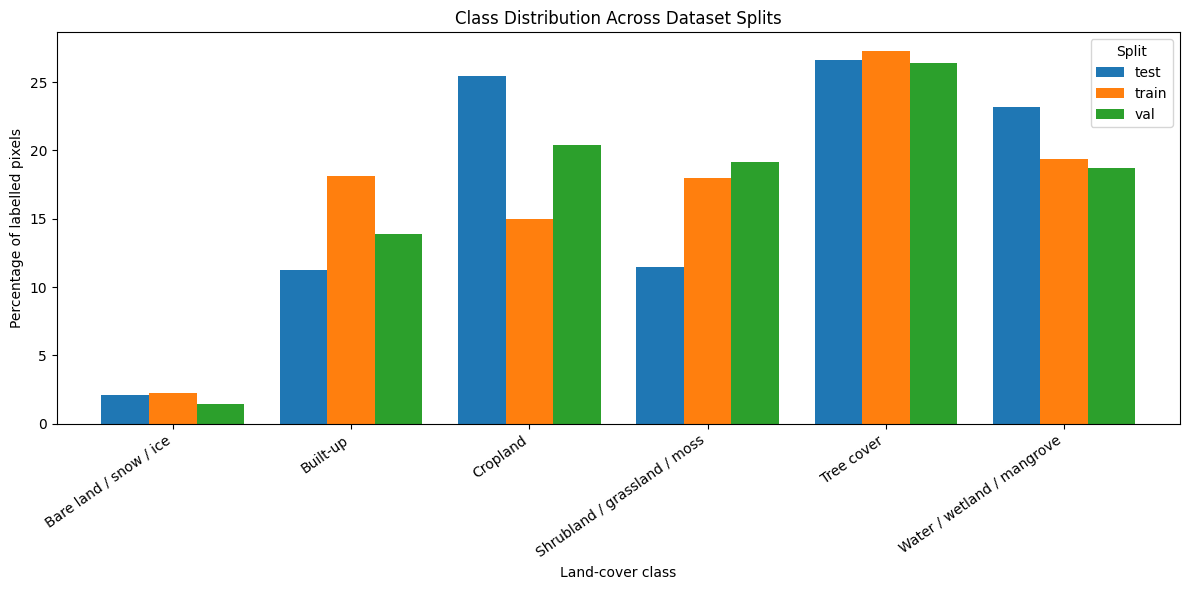

In [24]:
# ============================================================
# CLASS DISTRIBUTION BY DATASET SPLIT
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TILE_DIR = os.path.join(
    PROJECT_DIR, "data", "tiles"
)

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

IGNORE_LABEL = 255

class_counts = {}

for split in ["train", "val", "test"]:

    split_dir = os.path.join(TILE_DIR, split)

    counts = np.zeros(6, dtype=np.int64)

    for filename in os.listdir(split_dir):

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(split_dir, filename)

        with np.load(path) as data:

            labels = data["label"]

            for class_id in range(6):

                counts[class_id] += np.sum(
                    labels == class_id
                )

    class_counts[split] = counts


# ------------------------------------------------------------
# CREATE DISTRIBUTION TABLE
# ------------------------------------------------------------

rows = []

for split, counts in class_counts.items():

    total = counts.sum()

    for class_id, class_name in CLASS_NAMES.items():

        rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "pixel_count": int(counts[class_id]),
            "percentage": (
                counts[class_id] / total * 100
                if total > 0 else 0
            )
        })

distribution_df = pd.DataFrame(rows)

print("\nCLASS DISTRIBUTION BY SPLIT")
print("=" * 75)

print(
    distribution_df.pivot(
        index="class_name",
        columns="split",
        values="percentage"
    ).round(2)
)

print("\nPIXEL COUNTS")
print("=" * 75)

print(
    distribution_df.pivot(
        index="class_name",
        columns="split",
        values="pixel_count"
    )
)


# ------------------------------------------------------------
# VISUALIZE CLASS DISTRIBUTION
# ------------------------------------------------------------

pivot_df = distribution_df.pivot(
    index="class_name",
    columns="split",
    values="percentage"
)

ax = pivot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_ylabel("Percentage of labelled pixels")
ax.set_xlabel("Land-cover class")
ax.set_title("Class Distribution Across Dataset Splits")
ax.legend(title="Split")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plot_path = os.path.join(
    PROJECT_DIR,
    "results",
    "plots",
    "class_distribution_by_split.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

STEP 7 — FULL DATASET QUALITY VALIDATION

Dataset directory: /home/jovyan/vault/LULC_Project/data/tiles
Total NPZ files found: 500


Validating tiles:   0%|          | 0/500 [00:00<?, ?it/s]


TILE VALIDATION STATUS
status
warning    369
success    131

STATUS BY SPLIT
status  success  warning
split                   
test         38       62
train        71      249
val          22       58

SENTINEL-1 VALUE STATISTICS
minimum_db          : -47.7500
maximum_db          : 33.0000
mean_db             : -15.1505
std_db              : 6.5712
median_db           : -14.7266
p01_db              : -30.2344
p99_db              : -1.2959

MONTHLY VV/VH STATISTICS
 month band  mean_db  std_db  median_db
     1   VV  -11.568   5.097    -10.719
     1   VH  -19.086   5.554    -17.672
     2   VV  -11.590   5.119    -10.758
     2   VH  -19.104   5.527    -17.750
     3   VV  -11.774   5.269    -10.906
     3   VH  -19.139   5.643    -17.766
     4   VV  -11.875   5.291    -10.969
     4   VH  -19.113   5.677    -17.656
     5   VV  -11.555   5.222    -10.578
     5   VH  -18.901   5.709    -17.312
     6   VV  -11.456   5.350    -10.367
     6   VH  -18.688   5.645    -17.062
     7   

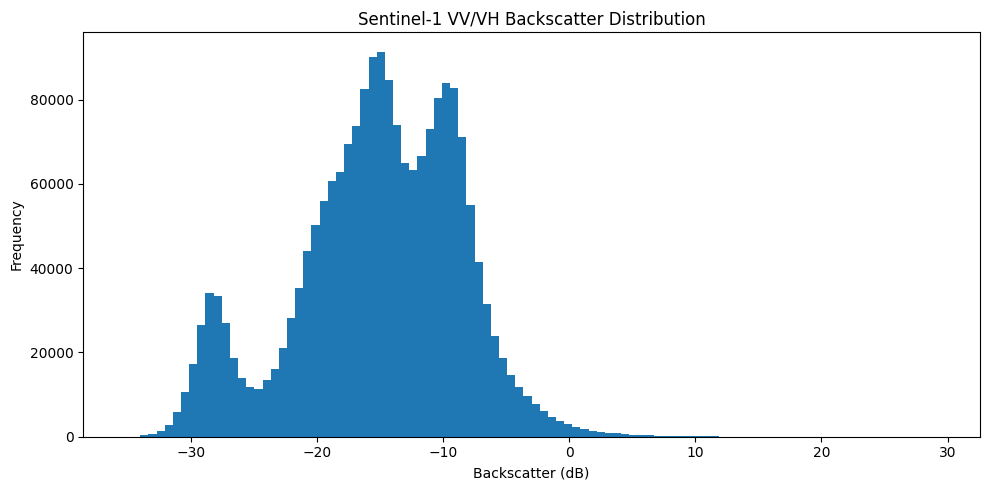

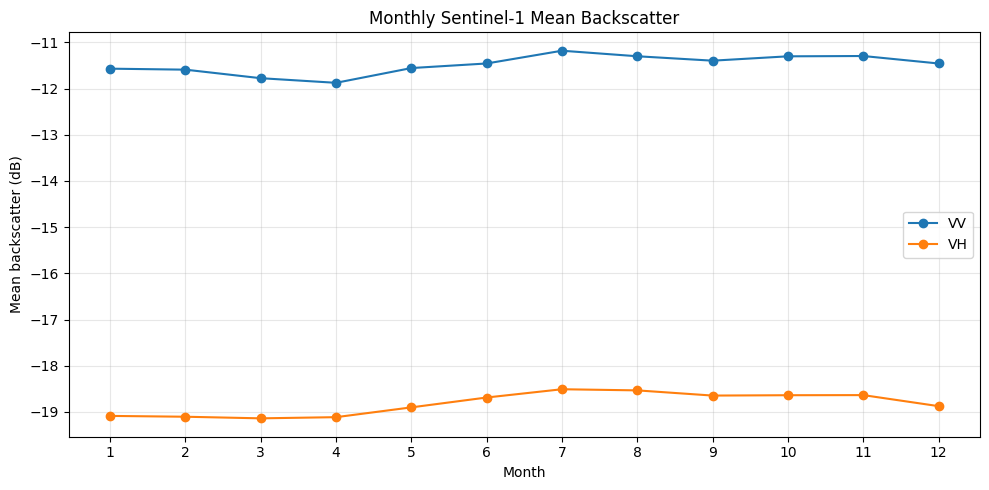

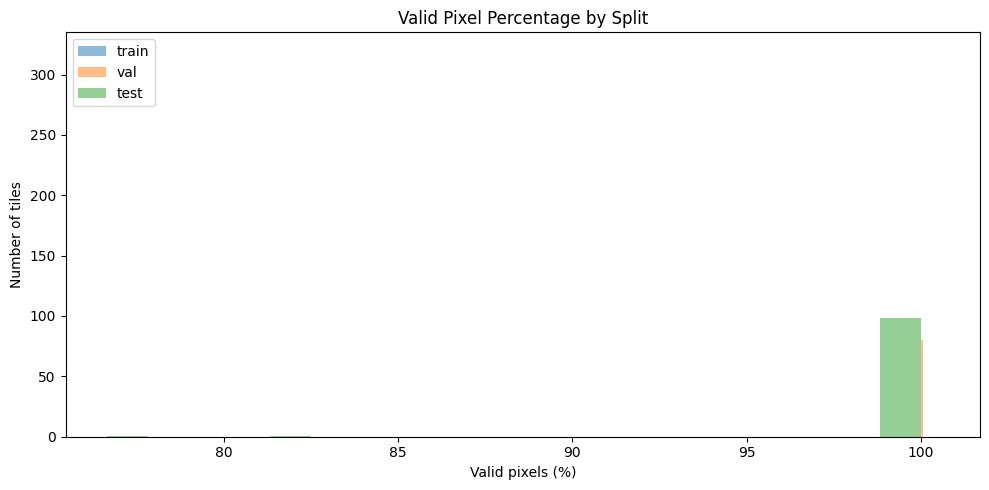


FINAL DATASET VALIDATION SUMMARY
Total tiles       : 500
Successful tiles  : 500
Warning tiles     : 369
Failed tiles      : 0

Split counts:
train     : 320
val       : 80
test      : 100

Saved reports:
/home/jovyan/vault/LULC_Project/data/metadata/dataset_validation.csv
/home/jovyan/vault/LULC_Project/data/metadata/monthly_s1_statistics.csv
/home/jovyan/vault/LULC_Project/data/metadata/validated_class_distribution.csv
/home/jovyan/vault/LULC_Project/results/metrics/dataset_validation_summary.json

Saved plots:
/home/jovyan/vault/LULC_Project/results/plots/s1_backscatter_distribution.png
/home/jovyan/vault/LULC_Project/results/plots/monthly_s1_mean_backscatter.png
/home/jovyan/vault/LULC_Project/results/plots/valid_pixel_distribution.png

No tiles failed the validation checks.

STEP 7 VALIDATION COMPLETED.


In [25]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# STEP 7 — FULL DATASET QUALITY VALIDATION
# ============================================================

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
DATA_DIR = PROJECT_DIR / "data" / "tiles"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"

for folder in [METADATA_DIR, PLOT_DIR, METRICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

EXPECTED_S1_SHAPE = (12, 2, 256, 256)
EXPECTED_LABEL_SHAPE = (256, 256)

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

VALID_LABELS = set(CLASS_NAMES.keys())
IGNORE_LABEL = 255
NODATA_VALUE = -9999

SPLITS = ["train", "val", "test"]

# ------------------------------------------------------------
# 1. Find all dataset files
# ------------------------------------------------------------

all_files = sorted(DATA_DIR.rglob("*.npz"))

print("=" * 65)
print("STEP 7 — FULL DATASET QUALITY VALIDATION")
print("=" * 65)

print(f"\nDataset directory: {DATA_DIR}")
print(f"Total NPZ files found: {len(all_files)}")

if len(all_files) == 0:
    raise FileNotFoundError(f"No .npz files found in {DATA_DIR}")

# ------------------------------------------------------------
# 2. Validate every tile
# ------------------------------------------------------------

records = []
class_pixel_counts = {split: {c: 0 for c in CLASS_NAMES}
                      for split in SPLITS}

total_valid_pixels = {split: 0 for split in SPLITS}

global_s1_values = []
monthly_stats = {
    month: {
        "VV": [],
        "VH": []
    }
    for month in range(1, 13)
}

for file_path in tqdm(all_files, desc="Validating tiles"):

    tile_id = file_path.stem

    # Determine split from folder structure or filename
    split = None
    for candidate in SPLITS:
        if candidate in file_path.parts:
            split = candidate
            break

    # Fallback: use collection log if necessary
    if split is None:
        split = "unknown"

    record = {
        "tile_id": tile_id,
        "split": split,
        "file": str(file_path),
        "file_size_mb": file_path.stat().st_size / (1024 ** 2),
        "status": "success",
        "errors": "",
        "warnings": ""
    }

    try:
        with np.load(file_path, allow_pickle=False) as data:

            required_keys = ["s1", "label"]

            missing_keys = [
                key for key in required_keys
                if key not in data.files
            ]

            if missing_keys:
                raise ValueError(
                    f"Missing required keys: {missing_keys}"
                )

            s1 = data["s1"]
            label = data["label"]

            monthly_counts = (
                data["monthly_image_counts"]
                if "monthly_image_counts" in data.files
                else None
            )

            stored_valid_pct = (
                float(data["valid_pixel_percentage"])
                if "valid_pixel_percentage" in data.files
                else np.nan
            )

            # ------------------------------------------------
            # Check shapes
            # ------------------------------------------------

            record["s1_shape_correct"] = (
                s1.shape == EXPECTED_S1_SHAPE
            )

            record["label_shape_correct"] = (
                label.shape == EXPECTED_LABEL_SHAPE
            )

            if s1.shape != EXPECTED_S1_SHAPE:
                record["errors"] += (
                    f"Wrong S1 shape: {s1.shape}; "
                )

            if label.shape != EXPECTED_LABEL_SHAPE:
                record["errors"] += (
                    f"Wrong label shape: {label.shape}; "
                )

            if s1.shape != EXPECTED_S1_SHAPE:
                raise ValueError(record["errors"])

            if label.shape != EXPECTED_LABEL_SHAPE:
                raise ValueError(record["errors"])

            # ------------------------------------------------
            # Check data types
            # ------------------------------------------------

            record["s1_dtype"] = str(s1.dtype)
            record["label_dtype"] = str(label.dtype)

            record["s1_float16"] = s1.dtype == np.float16
            record["label_uint8"] = label.dtype == np.uint8

            # ------------------------------------------------
            # Check Sentinel-1 values
            # ------------------------------------------------

            s1_finite = np.isfinite(s1)

            record["s1_nan_count"] = int(np.isnan(s1).sum())
            record["s1_inf_count"] = int(np.isinf(s1).sum())

            valid_s1 = (
                s1_finite &
                (s1 != NODATA_VALUE)
            )

            record["s1_nodata_count"] = int(
                (s1 == NODATA_VALUE).sum()
            )

            record["s1_valid_value_count"] = int(
                valid_s1.sum()
            )

            if valid_s1.any():

                values = s1[valid_s1].astype(np.float32)

                record["s1_min_db"] = float(values.min())
                record["s1_max_db"] = float(values.max())
                record["s1_mean_db"] = float(values.mean())
                record["s1_std_db"] = float(values.std())

                global_s1_values.append(values)

                # Collect per-month, per-band statistics
                for month_idx in range(12):

                    for band_idx, band_name in enumerate(
                        ["VV", "VH"]
                    ):

                        band = s1[month_idx, band_idx]

                        band_valid = (
                            np.isfinite(band) &
                            (band != NODATA_VALUE)
                        )

                        if band_valid.any():

                            band_values = band[
                                band_valid
                            ].astype(np.float32)

                            monthly_stats[
                                month_idx + 1
                            ][band_name].append(
                                band_values
                            )

                # Plausibility warning, not automatic rejection
                if values.min() < -50 or values.max() > 10:
                    record["warnings"] += (
                        "Unusual Sentinel-1 dB range; "
                    )

            else:

                record["s1_min_db"] = np.nan
                record["s1_max_db"] = np.nan
                record["s1_mean_db"] = np.nan
                record["s1_std_db"] = np.nan

                record["errors"] += "No valid S1 values; "

            # ------------------------------------------------
            # Check label values
            # ------------------------------------------------

            unique_labels = np.unique(label)

            unexpected_labels = [
                int(x) for x in unique_labels
                if int(x) not in VALID_LABELS
                and int(x) != IGNORE_LABEL
            ]

            record["unique_label_count"] = len(unique_labels)
            record["unexpected_labels"] = str(
                unexpected_labels
            )

            record["ignore_pixel_count"] = int(
                (label == IGNORE_LABEL).sum()
            )

            record["label_valid_pixel_count"] = int(
                np.isin(
                    label,
                    list(VALID_LABELS)
                ).sum()
            )

            if unexpected_labels:
                record["errors"] += (
                    f"Unexpected labels: {unexpected_labels}; "
                )

            # ------------------------------------------------
            # Recalculate valid pixels
            # ------------------------------------------------

            all_months_valid = valid_s1.all(axis=(0, 1))

            valid_labels = np.isin(
                label,
                list(VALID_LABELS)
            )

            jointly_valid = (
                all_months_valid &
                valid_labels
            )

            recomputed_valid_pct = (
                jointly_valid.sum() /
                (256 * 256)
            ) * 100

            record["recomputed_valid_pixel_pct"] = float(
                recomputed_valid_pct
            )

            record["stored_valid_pixel_pct"] = stored_valid_pct

            if np.isfinite(stored_valid_pct):
                record["valid_pct_difference"] = abs(
                    stored_valid_pct - recomputed_valid_pct
                )
            else:
                record["valid_pct_difference"] = np.nan

            if recomputed_valid_pct < 50:
                record["errors"] += (
                    "Valid pixel percentage below 50%; "
                )

            if (
                np.isfinite(stored_valid_pct)
                and abs(
                    stored_valid_pct - recomputed_valid_pct
                ) > 0.1
            ):
                record["warnings"] += (
                    "Stored and recalculated validity differ; "
                )

            # ------------------------------------------------
            # Monthly observation counts
            # ------------------------------------------------

            if monthly_counts is not None:

                record["monthly_counts_shape"] = str(
                    monthly_counts.shape
                )

                record["minimum_monthly_image_count"] = int(
                    monthly_counts.min()
                )

                record["maximum_monthly_image_count"] = int(
                    monthly_counts.max()
                )

                record["months_with_zero_images"] = int(
                    (monthly_counts == 0).sum()
                )

                if monthly_counts.shape != (12,):
                    record["errors"] += (
                        "Incorrect monthly count shape; "
                    )

                elif (monthly_counts <= 0).any():
                    record["errors"] += (
                        "Month with zero/negative observations; "
                    )

            else:

                record["monthly_counts_shape"] = "missing"
                record["minimum_monthly_image_count"] = np.nan
                record["maximum_monthly_image_count"] = np.nan
                record["months_with_zero_images"] = np.nan

                record["warnings"] += (
                    "Monthly image counts unavailable; "
                )

            # ------------------------------------------------
            # Class counts by split
            # ------------------------------------------------

            if split in SPLITS:

                for class_id in CLASS_NAMES:

                    count = int(
                        (label == class_id).sum()
                    )

                    class_pixel_counts[
                        split
                    ][class_id] += count

                total_valid_pixels[split] += int(
                    valid_labels.sum()
                )

    except Exception as e:

        record["status"] = "failed"
        record["errors"] += str(e)

    # Determine tile status
    if record["status"] == "success":

        if record["errors"]:
            record["status"] = "failed"

        elif record["warnings"]:
            record["status"] = "warning"

    records.append(record)


# ------------------------------------------------------------
# 3. Create validation report
# ------------------------------------------------------------

validation_df = pd.DataFrame(records)

validation_csv = (
    METADATA_DIR / "dataset_validation.csv"
)

validation_df.to_csv(
    validation_csv,
    index=False
)

# ------------------------------------------------------------
# 4. Print tile status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TILE VALIDATION STATUS")
print("=" * 65)

print(
    validation_df["status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSTATUS BY SPLIT")

print(
    validation_df.groupby(
        ["split", "status"]
    ).size().unstack(fill_value=0)
)

# ------------------------------------------------------------
# 5. Sentinel-1 overall statistics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SENTINEL-1 VALUE STATISTICS")
print("=" * 65)

if global_s1_values:

    all_values = np.concatenate(global_s1_values)

    s1_summary = {
        "minimum_db": float(np.min(all_values)),
        "maximum_db": float(np.max(all_values)),
        "mean_db": float(np.mean(all_values)),
        "std_db": float(np.std(all_values)),
        "median_db": float(np.median(all_values)),
        "p01_db": float(np.percentile(all_values, 1)),
        "p99_db": float(np.percentile(all_values, 99))
    }

    for key, value in s1_summary.items():
        print(f"{key:20s}: {value:.4f}")

else:
    s1_summary = {}
    print("No valid Sentinel-1 values found.")

# ------------------------------------------------------------
# 6. Monthly VV/VH statistics
# ------------------------------------------------------------

monthly_rows = []

for month in range(1, 13):

    for band_name in ["VV", "VH"]:

        arrays = monthly_stats[month][band_name]

        if arrays:

            values = np.concatenate(arrays)

            monthly_rows.append({
                "month": month,
                "band": band_name,
                "min_db": float(values.min()),
                "max_db": float(values.max()),
                "mean_db": float(values.mean()),
                "std_db": float(values.std()),
                "median_db": float(np.median(values)),
                "p01_db": float(np.percentile(values, 1)),
                "p99_db": float(np.percentile(values, 99))
            })

        else:

            monthly_rows.append({
                "month": month,
                "band": band_name,
                "min_db": np.nan,
                "max_db": np.nan,
                "mean_db": np.nan,
                "std_db": np.nan,
                "median_db": np.nan,
                "p01_db": np.nan,
                "p99_db": np.nan
            })

monthly_df = pd.DataFrame(monthly_rows)

print("\nMONTHLY VV/VH STATISTICS")

print(
    monthly_df[
        ["month", "band", "mean_db", "std_db", "median_db"]
    ].round(3).to_string(index=False)
)

monthly_df.to_csv(
    METADATA_DIR / "monthly_s1_statistics.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Class distribution from validation scan
# ------------------------------------------------------------

class_rows = []

for split in SPLITS:

    denominator = total_valid_pixels[split]

    for class_id, class_name in CLASS_NAMES.items():

        count = class_pixel_counts[split][class_id]

        percentage = (
            count / denominator * 100
            if denominator > 0 else 0
        )

        class_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "pixel_count": count,
            "percentage": percentage
        })

class_df = pd.DataFrame(class_rows)

class_df.to_csv(
    METADATA_DIR / "validated_class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Create plots
# ------------------------------------------------------------

# S1 value distribution
if global_s1_values:

    sample_values = all_values

    if len(sample_values) > 2_000_000:
        rng = np.random.default_rng(42)
        sample_values = rng.choice(
            sample_values,
            size=2_000_000,
            replace=False
        )

    plt.figure(figsize=(10, 5))
    plt.hist(sample_values, bins=100)
    plt.xlabel("Backscatter (dB)")
    plt.ylabel("Frequency")
    plt.title("Sentinel-1 VV/VH Backscatter Distribution")
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / "s1_backscatter_distribution.png",
        dpi=200
    )
    plt.show()

# Monthly mean backscatter
plt.figure(figsize=(10, 5))

for band_name in ["VV", "VH"]:

    subset = monthly_df[
        monthly_df["band"] == band_name
    ]

    plt.plot(
        subset["month"],
        subset["mean_db"],
        marker="o",
        label=band_name
    )

plt.xlabel("Month")
plt.ylabel("Mean backscatter (dB)")
plt.title("Monthly Sentinel-1 Mean Backscatter")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "monthly_s1_mean_backscatter.png",
    dpi=200
)
plt.show()

# Valid pixel percentage
plt.figure(figsize=(10, 5))

for split in SPLITS:

    subset = validation_df[
        validation_df["split"] == split
    ]

    if not subset.empty:
        plt.hist(
            subset["recomputed_valid_pixel_pct"].dropna(),
            bins=20,
            alpha=0.5,
            label=split
        )

plt.xlabel("Valid pixels (%)")
plt.ylabel("Number of tiles")
plt.title("Valid Pixel Percentage by Split")
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "valid_pixel_distribution.png",
    dpi=200
)
plt.show()

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

total_tiles = len(validation_df)

failed_tiles = int(
    (validation_df["status"] == "failed").sum()
)

warning_tiles = int(
    (validation_df["status"] == "warning").sum()
)

successful_tiles = total_tiles - failed_tiles

summary = {
    "total_tiles": total_tiles,
    "successful_tiles": successful_tiles,
    "warning_tiles": warning_tiles,
    "failed_tiles": failed_tiles,
    "split_counts": {
        split: int(
            (validation_df["split"] == split).sum()
        )
        for split in SPLITS
    },
    "sentinel1_statistics": s1_summary,
    "validation_csv": str(validation_csv),
    "monthly_statistics_csv": str(
        METADATA_DIR / "monthly_s1_statistics.csv"
    ),
    "class_distribution_csv": str(
        METADATA_DIR / "validated_class_distribution.csv"
    )
}

with open(
    METRICS_DIR / "dataset_validation_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 65)
print("FINAL DATASET VALIDATION SUMMARY")
print("=" * 65)

print(f"Total tiles       : {total_tiles}")
print(f"Successful tiles  : {successful_tiles}")
print(f"Warning tiles     : {warning_tiles}")
print(f"Failed tiles      : {failed_tiles}")

print("\nSplit counts:")

for split, count in summary["split_counts"].items():
    print(f"{split:10s}: {count}")

print("\nSaved reports:")
print(validation_csv)
print(METADATA_DIR / "monthly_s1_statistics.csv")
print(METADATA_DIR / "validated_class_distribution.csv")
print(METRICS_DIR / "dataset_validation_summary.json")

print("\nSaved plots:")
print(PLOT_DIR / "s1_backscatter_distribution.png")
print(PLOT_DIR / "monthly_s1_mean_backscatter.png")
print(PLOT_DIR / "valid_pixel_distribution.png")

if failed_tiles == 0:
    print("\nNo tiles failed the validation checks.")
else:
    print(
        f"\nATTENTION: {failed_tiles} tiles need investigation."
    )

print("\nSTEP 7 VALIDATION COMPLETED.")


In [26]:

import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
DATA_DIR = PROJECT_DIR / "data" / "tiles"
REPORT = PROJECT_DIR / "data" / "metadata" / "dataset_validation.csv"

df = pd.read_csv(REPORT)

print("=" * 65)
print("STEP 7A — WARNING INVESTIGATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Identify warning reasons
# ------------------------------------------------------------

warnings_df = df[df["status"] == "warning"].copy()

print(f"\nTiles with warnings: {len(warnings_df)}")

print("\nWARNING REASONS:")

range_warning = warnings_df[
    warnings_df["warnings"].str.contains(
        "Unusual Sentinel-1 dB range",
        na=False
    )
]

validity_warning = warnings_df[
    warnings_df["warnings"].str.contains(
        "Stored and recalculated validity differ",
        na=False
    )
]

missing_count_warning = warnings_df[
    warnings_df["warnings"].str.contains(
        "Monthly image counts unavailable",
        na=False
    )
]

print(f"Unusual backscatter range : {len(range_warning)}")
print(f"Validity percentage mismatch: {len(validity_warning)}")
print(f"Missing monthly counts   : {len(missing_count_warning)}")

print("\nWarning combinations:")
print(warnings_df["warnings"].value_counts().to_string())

# ------------------------------------------------------------
# 2. Inspect tiles with extreme maximum values
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TILES WITH HIGHEST BACKSCATTER MAXIMUMS")
print("=" * 65)

columns = [
    "tile_id",
    "split",
    "s1_min_db",
    "s1_max_db",
    "s1_mean_db",
    "recomputed_valid_pixel_pct",
    "stored_valid_pixel_pct",
    "warnings"
]

print(
    df.sort_values(
        "s1_max_db",
        ascending=False
    )[columns].head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 3. Locate extreme pixels in the original arrays
# ------------------------------------------------------------

extreme_records = []
threshold = 10.0

for file_path in sorted(DATA_DIR.rglob("*.npz")):

    with np.load(file_path, allow_pickle=False) as data:

        s1 = data["s1"].astype(np.float32)

        for month_idx in range(12):

            for band_idx, band_name in enumerate(["VV", "VH"]):

                band = s1[month_idx, band_idx]

                valid = (
                    np.isfinite(band) &
                    (band != -9999)
                )

                if not valid.any():
                    continue

                values = band[valid]

                if values.max() > threshold:

                    positions = np.argwhere(
                        valid & (band > threshold)
                    )

                    for row, col in positions[:20]:

                        extreme_records.append({
                            "tile_id": file_path.stem,
                            "month": month_idx + 1,
                            "band": band_name,
                            "row": int(row),
                            "col": int(col),
                            "value_db": float(band[row, col]),
                            "count_above_10_in_band": int(
                                (valid & (band > threshold)).sum()
                            )
                        })

extreme_df = pd.DataFrame(extreme_records)

print("\n" + "=" * 65)
print("EXTREME PIXEL INVESTIGATION")
print("=" * 65)

if len(extreme_df):

    print(f"Extreme pixel locations recorded: {len(extreme_df)}")
    print("\nHighest recorded values:")

    print(
        extreme_df.sort_values(
            "value_db",
            ascending=False
        ).head(30).to_string(index=False)
    )

    extreme_df.to_csv(
        PROJECT_DIR / "data" / "metadata" /
        "extreme_backscatter_pixels.csv",
        index=False
    )

else:
    print("No values above +10 dB found.")

# ------------------------------------------------------------
# 4. Count extreme pixels by month and band
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXTREME PIXEL COUNTS BY MONTH AND BAND")
print("=" * 65)

monthly_extreme = Counter()
total_extreme_pixels = 0

for file_path in sorted(DATA_DIR.rglob("*.npz")):

    with np.load(file_path, allow_pickle=False) as data:

        s1 = data["s1"].astype(np.float32)

        for month_idx in range(12):

            for band_idx, band_name in enumerate(["VV", "VH"]):

                band = s1[month_idx, band_idx]

                valid = (
                    np.isfinite(band) &
                    (band != -9999)
                )

                count = int(
                    (valid & (band > threshold)).sum()
                )

                monthly_extreme[
                    (month_idx + 1, band_name)
                ] += count

                total_extreme_pixels += count

for (month, band), count in sorted(monthly_extreme.items()):
    if count > 0:
        print(
            f"Month {month:02d} | {band}: {count:,} pixels"
        )

print(f"\nTotal pixels above +10 dB: {total_extreme_pixels:,}")

print("\nSTEP 7A COMPLETED.")


STEP 7A — WARNING INVESTIGATION

Tiles with warnings: 369

WARNING REASONS:
Unusual backscatter range : 369
Validity percentage mismatch: 0
Missing monthly counts   : 0

Warning combinations:
warnings
Unusual Sentinel-1 dB range;     369

TILES WITH HIGHEST BACKSCATTER MAXIMUMS
     tile_id split  s1_min_db  s1_max_db  s1_mean_db  recomputed_valid_pixel_pct  stored_valid_pixel_pct                      warnings
    hanoi_01  test -30.281250  33.000000  -11.209557                       100.0                   100.0 Unusual Sentinel-1 dB range; 
 shanghai_01 train -30.546875  33.000000  -11.503337                       100.0                   100.0 Unusual Sentinel-1 dB range; 
 shanghai_04 train -32.906250  32.812500  -17.100191                       100.0                   100.0 Unusual Sentinel-1 dB range; 
 shanghai_05 train -29.718750  32.781250  -12.337689                       100.0                   100.0 Unusual Sentinel-1 dB range; 
 shanghai_02 train -28.109375  32.281250  -10.

In [27]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
DATA_DIR = PROJECT_DIR / "data" / "tiles"
META_DIR = PROJECT_DIR / "data" / "metadata"

THRESHOLDS = [5, 10, 20]
tile_rows = []
month_rows = []
hotspot_rows = []
trajectory_rows = []

# Known extreme locations from Step 7A
KNOWN_PIXELS = [
    ("hanoi_01", 76, 154),
    ("shanghai_02", 25, 204),
    ("madrid_07", 77, 27),
    ("dhaka_03", 158, 202),
]

# ------------------------------------------------------------
# 1. Analyze every tile
# ------------------------------------------------------------

files = sorted(DATA_DIR.rglob("*.npz"))

for path in tqdm(files, desc="Analyzing anomalies"):

    with np.load(path, allow_pickle=False) as data:
        s1 = data["s1"].astype(np.float32)

    valid = np.isfinite(s1) & (s1 != -9999)
    values = s1[valid]

    row = {
        "tile_id": path.stem,
        "total_valid_values": len(values),
        "minimum_db": float(values.min()),
        "maximum_db": float(values.max()),
        "mean_db": float(values.mean()),
        "median_db": float(np.median(values)),
    }

    for threshold in THRESHOLDS:
        count = int((values > threshold).sum())
        row[f"count_above_{threshold}_db"] = count
        row[f"percentage_above_{threshold}_db"] = (
            count / len(values) * 100
        )

    tile_rows.append(row)

    # Per-month and per-band analysis
    for month_idx in range(12):
        for band_idx, band_name in enumerate(["VV", "VH"]):

            band = s1[month_idx, band_idx]
            band_valid = (
                np.isfinite(band) & (band != -9999)
            )
            band_values = band[band_valid]

            if len(band_values) == 0:
                continue

            month_row = {
                "tile_id": path.stem,
                "month": month_idx + 1,
                "band": band_name,
                "minimum_db": float(band_values.min()),
                "maximum_db": float(band_values.max()),
                "mean_db": float(band_values.mean()),
                "median_db": float(np.median(band_values)),
            }

            for threshold in THRESHOLDS:
                month_row[f"count_above_{threshold}_db"] = int(
                    (band_values > threshold).sum()
                )

            month_rows.append(month_row)

    # --------------------------------------------------------
    # 2. Check recurring extreme pixel locations
    # --------------------------------------------------------

    for band_idx, band_name in enumerate(["VV", "VH"]):

        for row_idx in range(256):
            for col_idx in range(256):

                pixel_series = s1[:, band_idx, row_idx, col_idx]

                valid_months = (
                    np.isfinite(pixel_series) &
                    (pixel_series != -9999)
                )

                if not valid_months.any():
                    continue

                extreme_months = (
                    valid_months &
                    (pixel_series > 10)
                )

                if extreme_months.sum() >= 3:

                    hotspot_rows.append({
                        "tile_id": path.stem,
                        "band": band_name,
                        "row": row_idx,
                        "col": col_idx,
                        "months_above_10_db": int(
                            extreme_months.sum()
                        ),
                        "maximum_db": float(
                            pixel_series[valid_months].max()
                        ),
                        "mean_db": float(
                            pixel_series[valid_months].mean()
                        )
                    })

    # --------------------------------------------------------
    # 3. Inspect selected known extreme pixels
    # --------------------------------------------------------

    for known_tile, row_idx, col_idx in KNOWN_PIXELS:

        if path.stem != known_tile:
            continue

        for band_idx, band_name in enumerate(["VV", "VH"]):

            series = s1[:, band_idx, row_idx, col_idx]

            for month_idx, value in enumerate(series):

                trajectory_rows.append({
                    "tile_id": known_tile,
                    "row": row_idx,
                    "col": col_idx,
                    "band": band_name,
                    "month": month_idx + 1,
                    "value_db": float(value)
                })


# ------------------------------------------------------------
# 4. Save reports
# ------------------------------------------------------------

tile_df = pd.DataFrame(tile_rows)
month_df = pd.DataFrame(month_rows)
hotspot_df = pd.DataFrame(hotspot_rows)
trajectory_df = pd.DataFrame(trajectory_rows)

tile_df.to_csv(
    META_DIR / "backscatter_anomaly_by_tile.csv",
    index=False
)

month_df.to_csv(
    META_DIR / "backscatter_anomaly_by_month.csv",
    index=False
)

hotspot_df.to_csv(
    META_DIR / "persistent_backscatter_hotspots.csv",
    index=False
)

trajectory_df.to_csv(
    META_DIR / "known_extreme_pixel_trajectories.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Print overall threshold statistics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BACKSCATTER THRESHOLD SUMMARY")
print("=" * 65)

total_values = tile_df["total_valid_values"].sum()

for threshold in THRESHOLDS:

    count = tile_df[f"count_above_{threshold}_db"].sum()

    print(
        f"> {threshold:2d} dB: {count:>12,} values "
        f"({count / total_values * 100:.5f}%)"
    )

# ------------------------------------------------------------
# 6. Highest anomaly tiles
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TOP 20 TILES BY PERCENTAGE ABOVE +10 dB")
print("=" * 65)

print(
    tile_df.sort_values(
        "percentage_above_10_db",
        ascending=False
    )[
        [
            "tile_id",
            "maximum_db",
            "count_above_10_db",
            "percentage_above_10_db"
        ]
    ].head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 7. Monthly and band summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MONTHLY ANOMALY SUMMARY")
print("=" * 65)

monthly_summary = (
    month_df.groupby(["month", "band"])
    .agg(
        mean_maximum_db=("maximum_db", "mean"),
        maximum_db=("maximum_db", "max"),
        count_above_10_db=("count_above_10_db", "sum"),
        count_above_20_db=("count_above_20_db", "sum")
    )
    .round(3)
)

print(monthly_summary.to_string())

# ------------------------------------------------------------
# 8. Persistent hotspots
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PERSISTENT HOTSPOTS")
print("=" * 65)

print(
    f"Pixels above +10 dB in at least 3 months: "
    f"{len(hotspot_df)}"
)

if not hotspot_df.empty:
    print(
        hotspot_df.sort_values(
            "months_above_10_db",
            ascending=False
        ).head(25).to_string(index=False)
    )

# ------------------------------------------------------------
# 9. Known pixel temporal trajectories
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("KNOWN EXTREME PIXEL TEMPORAL TRAJECTORIES")
print("=" * 65)

if not trajectory_df.empty:
    print(
        trajectory_df.pivot_table(
            index=["tile_id", "row", "col", "month"],
            columns="band",
            values="value_db"
        ).round(3).to_string()
    )

print("\nReports saved in:", META_DIR)
print("\nSTEP 7B COMPLETED.")


Analyzing anomalies:   0%|          | 0/500 [00:00<?, ?it/s]


BACKSCATTER THRESHOLD SUMMARY
>  5 dB:      895,930 values (0.11392%)
> 10 dB:      171,721 values (0.02184%)
> 20 dB:        6,378 values (0.00081%)

TOP 20 TILES BY PERCENTAGE ABOVE +10 dB
    tile_id  maximum_db  count_above_10_db  percentage_above_10_db
shanghai_03   32.125000              13110                0.833511
shanghai_10   31.093750               8521                0.541751
 beijing_08   31.453125               8144                0.517782
shanghai_01   33.000000               6140                0.390371
    pune_05   29.281250               4991                0.317319
shanghai_02   32.281250               3899                0.247892
  mumbai_08   30.828125               3694                0.234858
shanghai_06   29.343750               3566                0.226720
  mumbai_10   22.031250               3535                0.224749
  mumbai_02   25.218750               3492                0.222015
   tokyo_05   29.921875               3375                0.214577
   s

In [29]:
import os
from pathlib import Path

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")

CHECK_TILES = [
    "shanghai_03",
    "hanoi_01",
    "madrid_07",
    "dhaka_03",
    "addis_ababa_03",
    "toronto_06",
]

print("PROJECT DIRECTORY EXISTS:", PROJECT_DIR.exists())

print("\nDATA DIRECTORY CONTENTS:")
data_dir = PROJECT_DIR / "data"

if data_dir.exists():
    for item in data_dir.iterdir():
        print(item.name, " | directory:", item.is_dir())

print("\nSEARCHING FOR THE SIX TILE FILES:")

for tile_id in CHECK_TILES:
    matches = list(PROJECT_DIR.rglob(f"{tile_id}.npz"))
    print(f"\n{tile_id}:")
    if matches:
        for path in matches:
            print(" ", path)
    else:
        print("  NOT FOUND")

print("\nALL NPZ FILE LOCATIONS (FIRST 30):")

all_npz = list(PROJECT_DIR.rglob("*.npz"))

for path in all_npz[:30]:
    print(path)

print("\nTotal NPZ files found:", len(all_npz))

PROJECT DIRECTORY EXISTS: True

DATA DIRECTORY CONTENTS:
.ipynb_checkpoints  | directory: True
raw  | directory: True
tiles  | directory: True
metadata  | directory: True

SEARCHING FOR THE SIX TILE FILES:

shanghai_03:
  /home/jovyan/vault/LULC_Project/data/tiles/train/shanghai_03.npz

hanoi_01:
  /home/jovyan/vault/LULC_Project/data/tiles/test/hanoi_01.npz

madrid_07:
  /home/jovyan/vault/LULC_Project/data/tiles/train/madrid_07.npz

dhaka_03:
  /home/jovyan/vault/LULC_Project/data/tiles/train/dhaka_03.npz

addis_ababa_03:
  /home/jovyan/vault/LULC_Project/data/tiles/test/addis_ababa_03.npz

toronto_06:
  /home/jovyan/vault/LULC_Project/data/tiles/val/toronto_06.npz

ALL NPZ FILE LOCATIONS (FIRST 30):
/home/jovyan/vault/LULC_Project/data/tiles/train/berlin_01.npz
/home/jovyan/vault/LULC_Project/data/tiles/train/berlin_02.npz
/home/jovyan/vault/LULC_Project/data/tiles/train/berlin_03.npz
/home/jovyan/vault/LULC_Project/data/tiles/train/berlin_04.npz
/home/jovyan/vault/LULC_Project/data

In [30]:
# ============================================================
# STEP 7C — VERIFY ANOMALOUS VALUES AGAINST EARTH ENGINE
# Corrected dataset paths: train / val / test
# ============================================================

import os
import requests
import numpy as np
import pandas as pd
import rasterio
import ee
from tqdm.auto import tqdm

PROJECT_DIR = "/home/jovyan/vault/LULC_Project"
TILE_DIR = os.path.join(PROJECT_DIR, "data", "tiles")

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "data", "metadata",
    "tile_manifest_candidates.csv"
)

OUTPUT_PATH = os.path.join(
    PROJECT_DIR, "data", "metadata",
    "earth_engine_anomaly_verification.csv"
)

GEE_PROJECT_ID = "final-project-513714"
TILE_PX = 256
TILE_SIZE_M = 7680

CHECK_TILES = [
    "shanghai_03",
    "hanoi_01",
    "madrid_07",
    "dhaka_03",
    "addis_ababa_03",
    "toronto_06",
]

# ------------------------------------------------------------
# 1. EARTH ENGINE
# ------------------------------------------------------------

try:
    ee.Initialize(project=GEE_PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT_ID)

print("Earth Engine initialized.")

# ------------------------------------------------------------
# 2. MANIFEST
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH).set_index("tile_id")

S1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VV", "VH"])
)

print("Sentinel-1 collection prepared.")

# ------------------------------------------------------------
# 3. VERIFY
# ------------------------------------------------------------

results = []

for tile_id in tqdm(CHECK_TILES, desc="Verifying source data"):

    if tile_id not in manifest.index:
        print(f"Missing from manifest: {tile_id}")
        continue

    row = manifest.loc[tile_id]
    split = row["split"]

    npz_path = os.path.join(
        TILE_DIR, split, f"{tile_id}.npz"
    )

    if not os.path.exists(npz_path):
        print(f"Missing saved tile: {npz_path}")
        continue

    epsg = int(row["utm_epsg"])
    projection = ee.Projection(f"EPSG:{epsg}")

    half_size = TILE_SIZE_M / 2

    xmin = float(row["center_x_m"]) - half_size
    xmax = float(row["center_x_m"]) + half_size
    ymin = float(row["center_y_m"]) - half_size
    ymax = float(row["center_y_m"]) + half_size

    region = ee.Geometry.Rectangle(
        [xmin, ymin, xmax, ymax],
        proj=projection,
        geodesic=False
    )

    with np.load(npz_path) as data:
        original_s1 = data["s1"].astype(np.float32)

    monthly_images = []

    for month in range(1, 13):

        start = f"2021-{month:02d}-01"
        end = (
            "2022-01-01" if month == 12
            else f"2021-{month + 1:02d}-01"
        )

        monthly_image = (
            S1.filterDate(start, end)
            .median()
            .select(["VV", "VH"])
            .rename([
                f"VV_{month:02d}",
                f"VH_{month:02d}"
            ])
        )

        monthly_images.append(monthly_image)

    source_image = (
        ee.Image.cat(monthly_images)
        .toFloat()
        .unmask(-9999)
        .clip(region)
    )

    params = {
        "format": "GEO_TIFF",
        "region": region,
        "crs": f"EPSG:{epsg}",
        "dimensions": f"{TILE_PX}x{TILE_PX}"
    }

    try:
        url = source_image.getDownloadURL(params)
        response = requests.get(url, timeout=180)
        response.raise_for_status()

        with rasterio.MemoryFile(response.content) as memfile:
            with memfile.open() as ds:
                source_data = ds.read().astype(np.float32)

        if source_data.shape != (24, 256, 256):
            raise ValueError(
                f"Unexpected source shape: {source_data.shape}"
            )

        source_s1 = source_data.reshape(
            12, 2, 256, 256
        )

        for band_idx, band_name in enumerate(["VV", "VH"]):

            original = original_s1[:, band_idx]
            source = source_s1[:, band_idx]

            original_valid = (
                np.isfinite(original) & (original != -9999)
            )
            source_valid = (
                np.isfinite(source) & (source != -9999)
            )

            ov = original[original_valid]
            sv = source[source_valid]

            results.append({
                "tile_id": tile_id,
                "split": split,
                "band": band_name,

                "original_max_db": (
                    float(ov.max()) if ov.size else np.nan
                ),
                "source_max_db": (
                    float(sv.max()) if sv.size else np.nan
                ),

                "original_count_above_10": int((ov > 10).sum()),
                "source_count_above_10": int((sv > 10).sum()),

                "original_count_above_20": int((ov > 20).sum()),
                "source_count_above_20": int((sv > 20).sum()),

                "original_p99": (
                    float(np.percentile(ov, 99))
                    if ov.size else np.nan
                ),
                "source_p99": (
                    float(np.percentile(sv, 99))
                    if sv.size else np.nan
                ),

                "original_valid_values": int(ov.size),
                "source_valid_values": int(sv.size)
            })

        print(f"Verified: {tile_id}")

    except Exception as e:
        print(f"ERROR verifying {tile_id}: {e}")

# ------------------------------------------------------------
# 4. SAVE AND DISPLAY
# ------------------------------------------------------------

verification_df = pd.DataFrame(results)

if verification_df.empty:
    raise RuntimeError("No tiles were successfully verified.")

verification_df.to_csv(OUTPUT_PATH, index=False)

print("\n" + "=" * 65)
print("EARTH ENGINE SOURCE VERIFICATION")
print("=" * 65)

display(verification_df.round(3))

print("\nSaved:", OUTPUT_PATH)
print("Tiles verified:", verification_df["tile_id"].nunique())
print("\nSTEP 7C COMPLETED.")

Earth Engine initialized.
Sentinel-1 collection prepared.


Verifying source data:   0%|          | 0/6 [00:00<?, ?it/s]

Verified: shanghai_03
Verified: hanoi_01
Verified: madrid_07
Verified: dhaka_03
Verified: addis_ababa_03
Verified: toronto_06

EARTH ENGINE SOURCE VERIFICATION


,tile_id,split,band,original_max_db,source_max_db,original_count_above_10,source_count_above_10,original_count_above_20,source_count_above_20,original_p99,source_p99,original_valid_values,source_valid_values
0,shanghai_03,train,VV,32.125,32.117,12708,12719,709,710,11.906,11.906,786432,786432
1,shanghai_03,train,VH,26.625,26.622,402,403,31,31,1.425,1.425,786432,786432
2,hanoi_01,test,VV,30.484,30.486,499,500,37,37,2.254,2.255,786432,786432
3,hanoi_01,test,VH,33.000,32.985,106,106,9,9,-5.500,-5.500,786432,786432
4,madrid_07,train,VV,29.938,29.932,416,416,23,23,3.045,3.045,786432,786432
5,madrid_07,train,VH,15.547,15.546,18,18,0,0,-4.176,-4.176,786432,786432
6,dhaka_03,train,VV,30.812,30.816,323,323,15,15,2.490,2.491,786432,786432
7,dhaka_03,train,VH,11.406,11.409,2,2,0,0,-6.855,-6.856,786432,786432
8,addis_ababa_03,test,VV,22.484,22.484,907,908,19,19,4.258,4.259,786432,786432
9,addis_ababa_03,test,VH,17.766,17.763,65,65,0,0,-4.957,-4.955,786432,786432



Saved: /home/jovyan/vault/LULC_Project/data/metadata/earth_engine_anomaly_verification.csv
Tiles verified: 6

STEP 7C COMPLETED.


In [31]:

# ============================================================
# STEP 8 — FINALIZE RAW DATASET + PREPROCESSING
# Sentinel-1 only | 12 months | VV/VH | 6 LULC classes
#
# Raw data is READ ONLY.
# Processed data is saved separately in processed_dataset_v1.
# ============================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")

RAW_DIR = PROJECT_DIR / "data" / "tiles"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

# Separate versioned output: never overwrite original data.
PROCESSED_DIR = PROJECT_DIR / "processed_dataset_v1"

SPLITS = ["train", "val", "test"]

EXPECTED_COUNTS = {
    "train": 320,
    "val": 80,
    "test": 100
}

EXPECTED_S1_SHAPE = (12, 2, 256, 256)
EXPECTED_LABEL_SHAPE = (256, 256)

VALID_CLASSES = set(range(6))
IGNORE_LABEL = 255

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

BANDS = ["VV", "VH"]

# Deterministic sampling for normalization statistics.
RANDOM_SEED = 42
SAMPLES_PER_TILE_PER_BAND = 20000

# ------------------------------------------------------------
# 2. CHECK PROJECT AND RAW DATA
# ------------------------------------------------------------

assert PROJECT_DIR.exists(), "Project directory missing."
assert RAW_DIR.exists(), "Raw tile directory missing."
assert METADATA_DIR.exists(), "Metadata directory missing."

print("=" * 70)
print("STEP 8 — DATASET FINALIZATION")
print("=" * 70)

for split in SPLITS:
    split_dir = RAW_DIR / split
    assert split_dir.exists(), f"Missing split directory: {split_dir}"

    files = sorted(split_dir.glob("*.npz"))

    print(f"{split.upper():5s}: {len(files)} tiles")

    assert len(files) == EXPECTED_COUNTS[split], (
        f"Expected {EXPECTED_COUNTS[split]} {split} tiles, "
        f"found {len(files)}"
    )

# ------------------------------------------------------------
# 3. CREATE VERSIONED OUTPUT DIRECTORIES
# ------------------------------------------------------------

for split in SPLITS:
    (PROCESSED_DIR / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (PROCESSED_DIR / split / "masks").mkdir(
        parents=True, exist_ok=True
    )

print("\nProcessed dataset directory:")
print(PROCESSED_DIR)

# ------------------------------------------------------------
# 4. LOAD AND VALIDATE TILE HELPER
# ------------------------------------------------------------

def load_tile(path):

    with np.load(path) as data:
        s1 = data["s1"].astype(np.float32)
        label = data["label"].astype(np.uint8)

    if s1.shape != EXPECTED_S1_SHAPE:
        raise ValueError(
            f"{path.name}: incorrect S1 shape {s1.shape}"
        )

    if label.shape != EXPECTED_LABEL_SHAPE:
        raise ValueError(
            f"{path.name}: incorrect label shape {label.shape}"
        )

    if not np.isfinite(s1).all():
        raise ValueError(f"{path.name}: non-finite S1 values")

    label_values = set(np.unique(label).tolist())

    if not label_values.issubset(VALID_CLASSES | {IGNORE_LABEL}):
        raise ValueError(
            f"{path.name}: unexpected labels {label_values}"
        )

    valid_s1 = (s1 != -9999)

    if not valid_s1.any():
        raise ValueError(f"{path.name}: no valid S1 observations")

    return s1, label, valid_s1


# ------------------------------------------------------------
# 5. COMPUTE TRAINING-ONLY ROBUST STATISTICS
# ------------------------------------------------------------

print("\nCalculating training-only normalization statistics...")

rng = np.random.default_rng(RANDOM_SEED)

training_samples = {
    "VV": [],
    "VH": []
}

train_files = sorted(
    (RAW_DIR / "train").glob("*.npz")
)

for path in tqdm(train_files, desc="Sampling training tiles"):

    s1, label, valid = load_tile(path)

    for band_idx, band_name in enumerate(BANDS):

        values = s1[:, band_idx].reshape(-1)
        valid_values = valid[:, band_idx].reshape(-1)

        values = values[valid_values]

        if values.size == 0:
            raise ValueError(
                f"No valid {band_name} values in {path.name}"
            )

        n = min(SAMPLES_PER_TILE_PER_BAND, values.size)

        indices = rng.choice(
            values.size,
            size=n,
            replace=False
        )

        training_samples[band_name].append(
            values[indices]
        )

normalization = {}

for band_name in BANDS:

    values = np.concatenate(training_samples[band_name])

    q25, median, q75 = np.percentile(
        values, [25, 50, 75]
    )

    iqr = float(q75 - q25)

    if iqr <= 0:
        raise ValueError(
            f"Invalid IQR for {band_name}: {iqr}"
        )

    normalization[band_name] = {
        "median_db": float(median),
        "q25_db": float(q25),
        "q75_db": float(q75),
        "iqr_db": iqr,
        "sample_count": int(values.size)
    }

print("\nTRAINING-ONLY NORMALIZATION STATISTICS")

for band_name in BANDS:
    print(f"\n{band_name}:")
    for key, value in normalization[band_name].items():
        print(f"  {key}: {value}")

# ------------------------------------------------------------
# 6. NORMALIZE AND SAVE ALL SPLITS
# ------------------------------------------------------------

print("\nCreating processed dataset...")

processing_records = []
class_pixel_counts = {
    split: {c: 0 for c in range(6)}
    for split in SPLITS
}

for split in SPLITS:

    files = sorted((RAW_DIR / split).glob("*.npz"))

    for path in tqdm(files, desc=f"Processing {split}"):

        s1, label, valid = load_tile(path)

        # Robust scaling using TRAIN statistics only.
        # No arbitrary clipping is applied.
        processed = np.zeros(
            EXPECTED_S1_SHAPE,
            dtype=np.float32
        )

        for band_idx, band_name in enumerate(BANDS):

            median = normalization[band_name]["median_db"]
            iqr = normalization[band_name]["iqr_db"]

            band_data = s1[:, band_idx]

            normalized = (band_data - median) / iqr

            # Keep invalid observations at zero after normalization.
            normalized[~valid[:, band_idx]] = 0.0

            processed[:, band_idx] = normalized

        if not np.isfinite(processed).all():
            raise ValueError(
                f"Non-finite processed values: {path.name}"
            )

        # Preserve the temporal dimension:
        # (12 months, 2 bands, 256, 256)
        image_out = (
            PROCESSED_DIR / split / "images" /
            f"{path.stem}.npy"
        )

        mask_out = (
            PROCESSED_DIR / split / "masks" /
            f"{path.stem}.npy"
        )

        np.save(image_out, processed)
        np.save(mask_out, label)

        for class_id in range(6):
            class_pixel_counts[split][class_id] += int(
                np.sum(label == class_id)
            )

        processing_records.append({
            "tile_id": path.stem,
            "split": split,
            "image_path": str(image_out.relative_to(PROJECT_DIR)),
            "mask_path": str(mask_out.relative_to(PROJECT_DIR)),
            "image_shape": str(processed.shape),
            "mask_shape": str(label.shape),
            "image_dtype": str(processed.dtype),
            "mask_dtype": str(label.dtype),
            "valid_s1_fraction": float(valid.mean()),
            "ignore_label_pixels": int(
                np.sum(label == IGNORE_LABEL)
            )
        })

# ------------------------------------------------------------
# 7. SAVE PREPROCESSING MANIFEST
# ------------------------------------------------------------

processing_df = pd.DataFrame(processing_records)

manifest_out = (
    METADATA_DIR / "preprocessing_manifest.csv"
)

processing_df.to_csv(manifest_out, index=False)

# ------------------------------------------------------------
# 8. SAVE CLASS DISTRIBUTION
# ------------------------------------------------------------

class_rows = []

for split in SPLITS:

    total = sum(class_pixel_counts[split].values())

    for class_id in range(6):

        count = class_pixel_counts[split][class_id]

        class_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "pixel_count": count,
            "percentage": (
                100 * count / total if total else 0
            )
        })

class_df = pd.DataFrame(class_rows)

class_out = (
    METADATA_DIR / "final_class_distribution.csv"
)

class_df.to_csv(class_out, index=False)

# ------------------------------------------------------------
# 9. SAVE FINAL DATASET METADATA
# ------------------------------------------------------------

raw_tile_counts = {
    split: len(list((RAW_DIR / split).glob("*.npz")))
    for split in SPLITS
}

raw_size_bytes = sum(
    p.stat().st_size
    for split in SPLITS
    for p in (RAW_DIR / split).glob("*.npz")
)

processed_size_bytes = sum(
    p.stat().st_size
    for split in SPLITS
    for folder in ["images", "masks"]
    for p in (PROCESSED_DIR / split / folder).glob("*.npy")
)

final_metadata = {
    "dataset_version": "1.0",
    "finalized_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "raw_dataset": {
        "location": str(RAW_DIR),
        "tile_counts": raw_tile_counts,
        "total_tiles": int(sum(raw_tile_counts.values())),
        "size_bytes": int(raw_size_bytes),
        "size_gb": round(raw_size_bytes / (1024**3), 4),
        "original_files_modified": False
    },

    "processed_dataset": {
        "location": str(PROCESSED_DIR),
        "total_tiles": int(len(processing_records)),
        "size_bytes": int(processed_size_bytes),
        "size_gb": round(processed_size_bytes / (1024**3), 4),
        "image_shape": list(EXPECTED_S1_SHAPE),
        "image_dtype": "float32",
        "mask_shape": list(EXPECTED_LABEL_SHAPE),
        "mask_dtype": "uint8"
    },

    "input": {
        "source": "COPERNICUS/S1_GRD",
        "bands": BANDS,
        "months": list(range(1, 13)),
        "year": 2021,
        "calibration": "Earth Engine Sentinel-1 GRD dB",
        "additional_db_conversion": False
    },

    "labels": {
        "source": "ESA WorldCover 2021",
        "classes": CLASS_NAMES,
        "ignore_label": IGNORE_LABEL,
        "monthly_ground_truth": False,
        "description": (
            "Annual 2021 reference labels used to supervise "
            "the 12-month Sentinel-1 input sequence."
        )
    },

    "normalization": {
        "method": "Robust median/IQR scaling",
        "formula": "(value - training_median) / training_IQR",
        "statistics_source": "Training split only",
        "clipping_applied": False,
        "statistics": normalization
    },

    "splits": {
        "train": {"tiles": 320, "cities": 32},
        "val": {"tiles": 80, "cities": 8},
        "test": {"tiles": 100, "cities": 10}
    }
}

metadata_out = (
    METADATA_DIR / "final_dataset_metadata_v1.json"
)

with open(metadata_out, "w") as f:
    json.dump(final_metadata, f, indent=4)

# ------------------------------------------------------------
# 10. FINAL PROCESSED DATA VALIDATION
# ------------------------------------------------------------

print("\nValidating processed output...")

validation_results = []

for split in SPLITS:

    image_files = sorted(
        (PROCESSED_DIR / split / "images").glob("*.npy")
    )

    mask_files = sorted(
        (PROCESSED_DIR / split / "masks").glob("*.npy")
    )

    assert len(image_files) == EXPECTED_COUNTS[split]
    assert len(mask_files) == EXPECTED_COUNTS[split]

    for image_path, mask_path in zip(image_files, mask_files):

        image = np.load(image_path, mmap_mode="r")
        mask = np.load(mask_path, mmap_mode="r")

        assert image.shape == EXPECTED_S1_SHAPE
        assert mask.shape == EXPECTED_LABEL_SHAPE
        assert image.dtype == np.float32
        assert mask.dtype == np.uint8
        assert np.isfinite(image).all()

        validation_results.append({
            "tile_id": image_path.stem,
            "split": split,
            "image_valid": True,
            "mask_valid": True
        })

validation_df = pd.DataFrame(validation_results)

assert len(validation_df) == 500
assert validation_df["image_valid"].all()
assert validation_df["mask_valid"].all()

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 8 — FINALIZATION SUMMARY")
print("=" * 70)

print("\nRAW DATASET")
print("Tiles:", sum(raw_tile_counts.values()))
print("Size:", round(raw_size_bytes / (1024**3), 3), "GB")
print("Original data modified: NO")

print("\nPROCESSED DATASET")
print("Tiles:", len(processing_records))
print("Size:", round(processed_size_bytes / (1024**3), 3), "GB")
print("Image shape:", EXPECTED_S1_SHAPE)
print("Mask shape:", EXPECTED_LABEL_SHAPE)

print("\nSPLIT COUNTS")
print(processing_df.groupby("split").size())

print("\nCLASS DISTRIBUTION")
display(
    class_df.pivot(
        index="class_name",
        columns="split",
        values="percentage"
    ).round(2)
)

print("\nNORMALIZATION")
for band_name in BANDS:
    print(
        band_name,
        "| median:",
        round(normalization[band_name]["median_db"], 4),
        "| IQR:",
        round(normalization[band_name]["iqr_db"], 4)
    )

print("\nVALIDATION")
print("Processed files checked:", len(validation_df))
print("Invalid files:", 0)

print("\nOUTPUTS")
print("Processed dataset:", PROCESSED_DIR)
print("Processing manifest:", manifest_out)
print("Class distribution:", class_out)
print("Final metadata:", metadata_out)

print("\n" + "=" * 70)
print("STEP 8 COMPLETED SUCCESSFULLY")
print("RAW DATASET VERSION 1.0 — FROZEN")
print("=" * 70)


STEP 8 — DATASET FINALIZATION
TRAIN: 320 tiles
VAL  : 80 tiles
TEST : 100 tiles

Processed dataset directory:
/home/jovyan/vault/LULC_Project/processed_dataset_v1

Calculating training-only normalization statistics...


Sampling training tiles:   0%|          | 0/320 [00:00<?, ?it/s]


TRAINING-ONLY NORMALIZATION STATISTICS

VV:
  median_db: -10.296875
  q25_db: -13.8203125
  q75_db: -8.0703125
  iqr_db: 5.75
  sample_count: 6400000

VH:
  median_db: -16.9375
  q25_db: -21.4375
  q75_db: -14.671875
  iqr_db: 6.765625
  sample_count: 6400000

Creating processed dataset...


Processing train:   0%|          | 0/320 [00:00<?, ?it/s]

Processing val:   0%|          | 0/80 [00:00<?, ?it/s]

Processing test:   0%|          | 0/100 [00:00<?, ?it/s]


Validating processed output...

STEP 8 — FINALIZATION SUMMARY

RAW DATASET
Tiles: 500
Size: 1.107 GB
Original data modified: NO

PROCESSED DATASET
Tiles: 500
Size: 2.96 GB
Image shape: (12, 2, 256, 256)
Mask shape: (256, 256)

SPLIT COUNTS
split
test     100
train    320
val       80
dtype: int64

CLASS DISTRIBUTION


split,test,train,val
class_name,,,
Bare land / snow / ice,2.06,2.21,1.45
Built-up,11.22,18.09,13.86
Cropland,25.48,15.00,20.42
Shrubland / grassland / moss,11.47,18.01,19.18
Tree cover,26.60,27.28,26.38
Water / wetland / mangrove,23.17,19.41,18.70



NORMALIZATION
VV | median: -10.2969 | IQR: 5.75
VH | median: -16.9375 | IQR: 6.7656

VALIDATION
Processed files checked: 500
Invalid files: 0

OUTPUTS
Processed dataset: /home/jovyan/vault/LULC_Project/processed_dataset_v1
Processing manifest: /home/jovyan/vault/LULC_Project/data/metadata/preprocessing_manifest.csv
Class distribution: /home/jovyan/vault/LULC_Project/data/metadata/final_class_distribution.csv
Final metadata: /home/jovyan/vault/LULC_Project/data/metadata/final_dataset_metadata_v1.json

STEP 8 COMPLETED SUCCESSFULLY
RAW DATASET VERSION 1.0 — FROZEN


PREPROCESSING VISUAL QUALITY ASSURANCE

TRAIN
Images: 320
Masks: 320
Missing masks: 0
Missing images: 0

VAL
Images: 80
Masks: 80
Missing masks: 0
Missing images: 0

TEST
Images: 100
Masks: 100
Missing masks: 0
Missing images: 0

TRAIN SAMPLE: berlin_08
Image shape: (12, 2, 256, 256)
Image dtype: float32
Mask shape: (256, 256)
Mask dtype: uint8
Label values: [0, 1, 2, 3, 4, 5]
Valid labelled pixels: 100.00%

VAL SAMPLE: accra_04
Image shape: (12, 2, 256, 256)
Image dtype: float32
Mask shape: (256, 256)
Mask dtype: uint8
Label values: [5]
Valid labelled pixels: 100.00%

TEST SAMPLE: prague_05
Image shape: (12, 2, 256, 256)
Image dtype: float32
Mask shape: (256, 256)
Mask dtype: uint8
Label values: [0, 1, 2, 3, 4, 5]
Valid labelled pixels: 100.00%


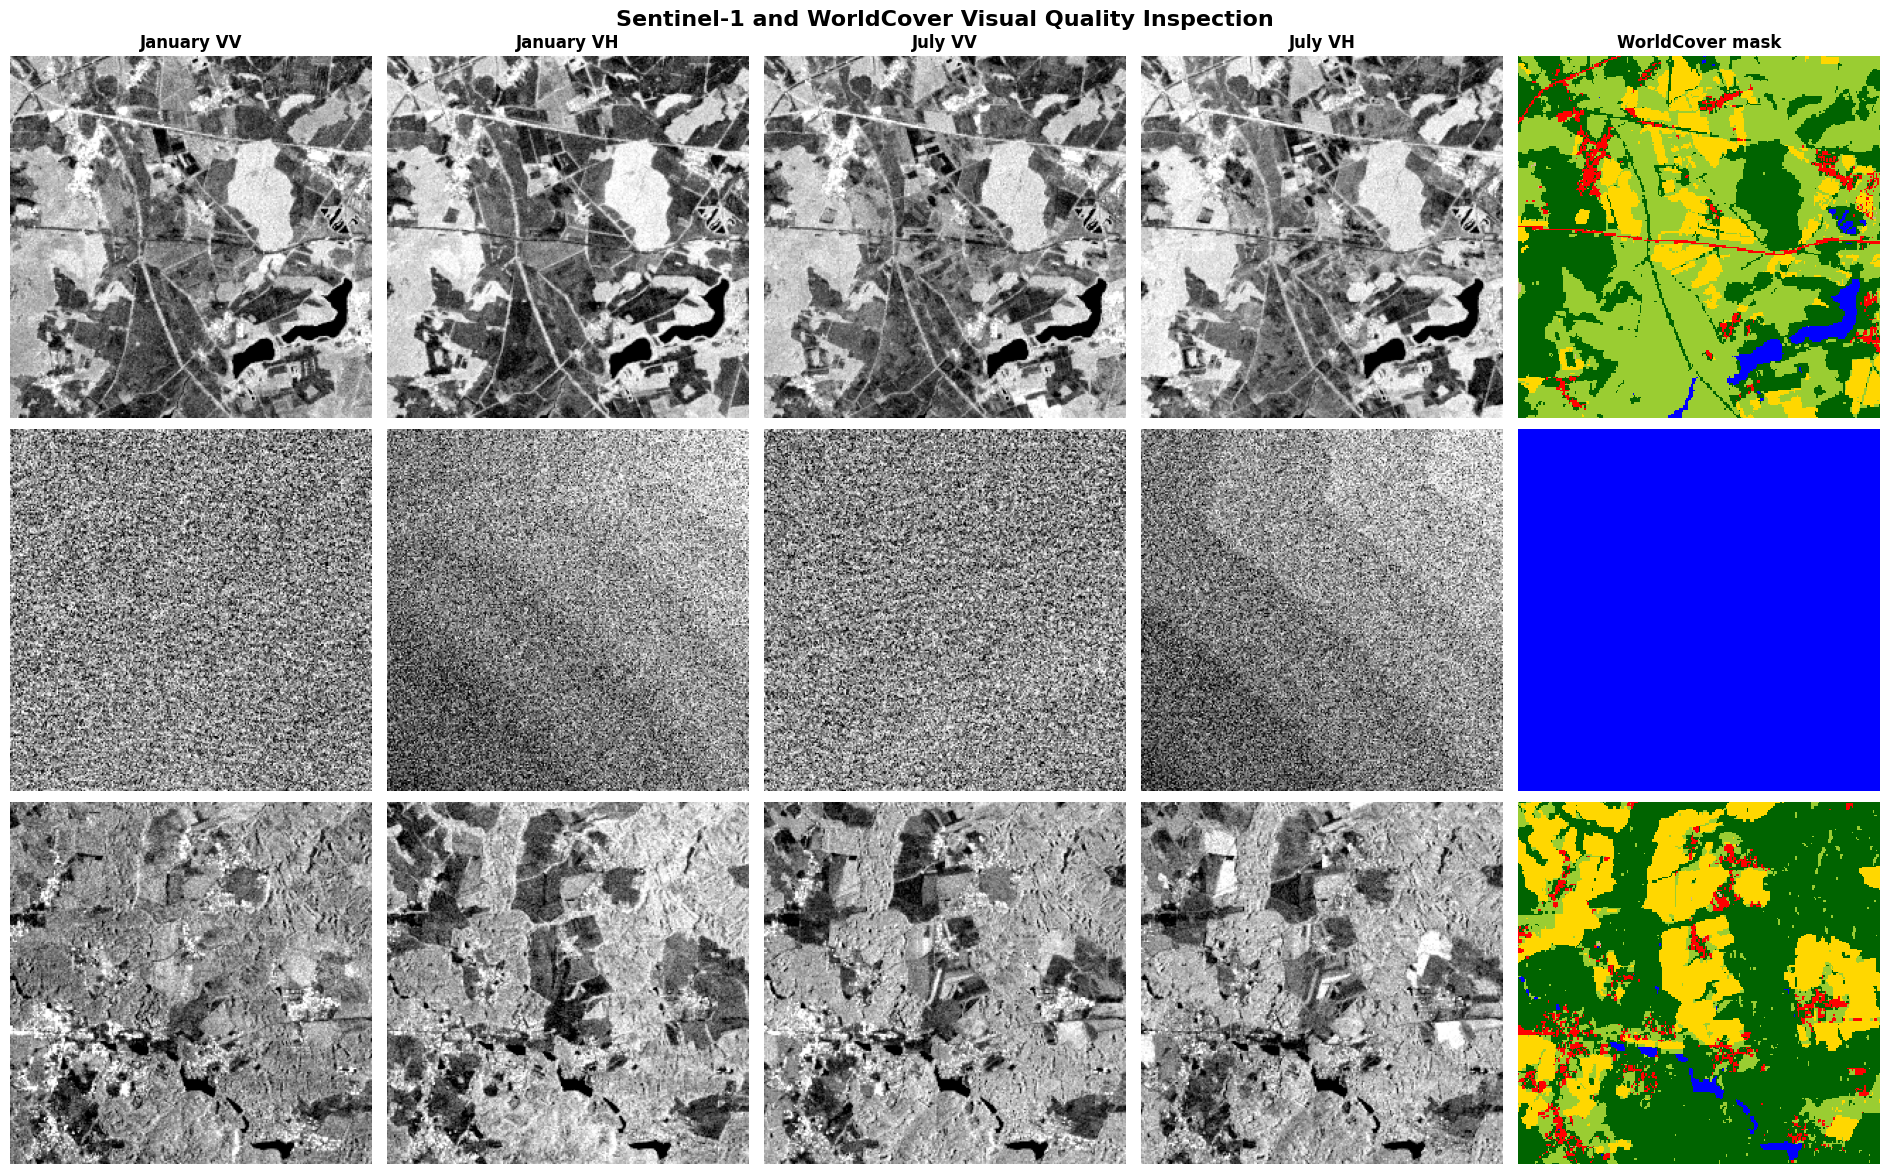


Visual inspection plot saved to:
/home/jovyan/vault/LULC_Project/results/plots/preprocessing_visual_qa_v1.png
TRAIN VV: min=-2.590, max=2.978, mean=-0.375, std=0.489
TRAIN VH: min=-1.949, max=2.493, mean=-0.319, std=0.498
VAL VV: min=-3.236, max=-0.709, mean=-1.901, std=0.270
VAL VH: min=-2.282, max=-1.192, mean=-1.671, std=0.100
TEST VV: min=-2.505, max=3.662, mean=0.069, std=0.362
TEST VH: min=-1.649, max=2.935, mean=0.038, std=0.357


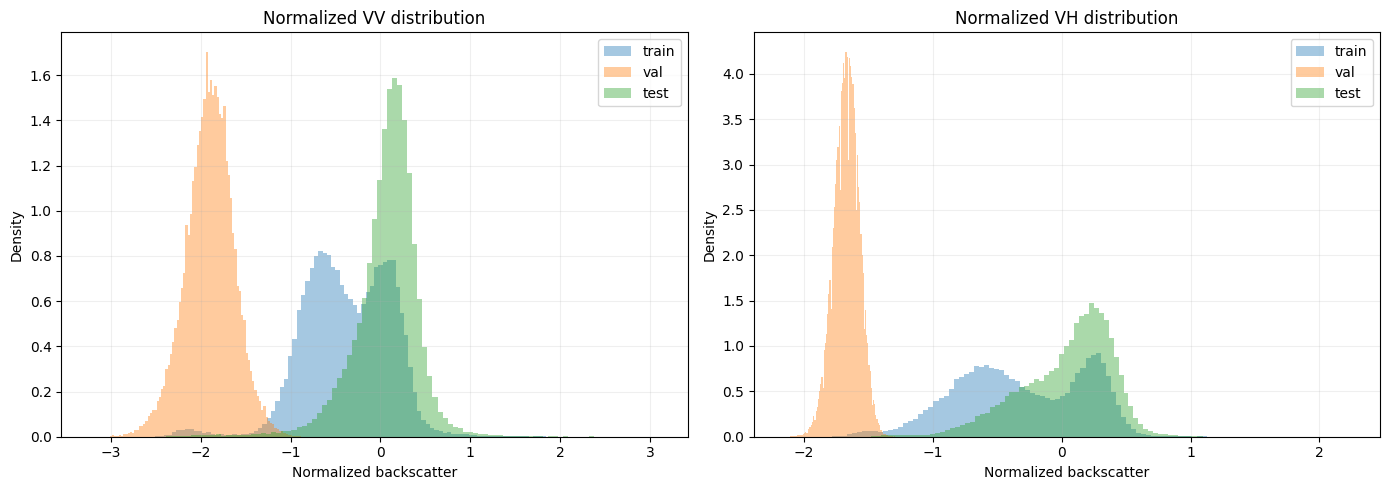


Distribution plot saved to:
/home/jovyan/vault/LULC_Project/results/plots/preprocessing_normalized_distributions.png

VISUAL QA CHECK COMPLETE
Inspect the displayed images before proceeding.


In [32]:

# ============================================================
# PREPROCESSING STEP 1 — VISUAL QUALITY ASSURANCE
# Inspect Sentinel-1 imagery and WorldCover masks
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import random
import json

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
DATA_DIR = PROJECT_DIR / "processed_dataset_v1"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]

CLASS_NAMES = [
    "Tree cover",
    "Shrub/grass/moss",
    "Cropland",
    "Built-up",
    "Bare/snow/ice",
    "Water/wetland"
]

# Consistent colours for the six classes
CLASS_COLORS = [
    "#006400",
    "#9ACD32",
    "#FFD700",
    "#FF0000",
    "#D2B48C",
    "#0000FF"
]

CLASS_CMAP = ListedColormap(CLASS_COLORS)
CLASS_CMAP.set_bad(color="black")
CLASS_NORM = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    CLASS_CMAP.N
)

random.seed(42)
np.random.seed(42)

# ------------------------------------------------------------
# 2. CHECK DATASET STRUCTURE
# ------------------------------------------------------------

print("=" * 70)
print("PREPROCESSING VISUAL QUALITY ASSURANCE")
print("=" * 70)

sample_files = {}

for split in SPLITS:
    image_dir = DATA_DIR / split / "images"
    mask_dir = DATA_DIR / split / "masks"

    image_files = sorted(image_dir.glob("*.npy"))
    mask_files = sorted(mask_dir.glob("*.npy"))

    image_names = {f.stem for f in image_files}
    mask_names = {f.stem for f in mask_files}

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("Masks:", len(mask_files))
    print("Missing masks:", len(image_names - mask_names))
    print("Missing images:", len(mask_names - image_names))

    if image_names != mask_names:
        raise ValueError(
            f"Image-mask filename mismatch in {split} split."
        )

    if not image_files:
        raise ValueError(f"No images found in {image_dir}")

    sample_files[split] = random.choice(image_files)

# ------------------------------------------------------------
# 3. LOAD AND VALIDATE SAMPLES
# ------------------------------------------------------------

samples = {}

for split, image_path in sample_files.items():

    mask_path = DATA_DIR / split / "masks" / image_path.name

    image = np.load(image_path)
    mask = np.load(mask_path)

    print(f"\n{split.upper()} SAMPLE: {image_path.stem}")
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Mask shape:", mask.shape)
    print("Mask dtype:", mask.dtype)

    if image.shape != (12, 2, 256, 256):
        raise ValueError(f"Unexpected image shape: {image.shape}")

    if mask.shape != (256, 256):
        raise ValueError(f"Unexpected mask shape: {mask.shape}")

    if not np.isfinite(image).all():
        raise ValueError(f"Non-finite image values: {image_path.name}")

    valid_labels = set(np.unique(mask).tolist())
    allowed_labels = set(range(6)) | {255}

    if not valid_labels.issubset(allowed_labels):
        raise ValueError(
            f"Unexpected mask labels: {valid_labels}"
        )

    samples[split] = {
        "image": image,
        "mask": mask,
        "name": image_path.stem
    }

    print("Label values:", sorted(valid_labels))
    print("Valid labelled pixels:",
          f"{np.mean(mask != 255) * 100:.2f}%")

# ------------------------------------------------------------
# 4. VISUALIZE VV, VH AND MASKS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=5,
    figsize=(19, 12)
)

column_titles = [
    "January VV",
    "January VH",
    "July VV",
    "July VH",
    "WorldCover mask"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight="bold")

for row, split in enumerate(SPLITS):

    image = samples[split]["image"]
    mask = samples[split]["mask"]
    tile_name = samples[split]["name"]

    # Month indices: January = 0, July = 6
    panels = [
        image[0, 0],
        image[0, 1],
        image[6, 0],
        image[6, 1]
    ]

    for col, band_image in enumerate(panels):

        valid = np.isfinite(band_image)

        if valid.any():
            vmin, vmax = np.percentile(
                band_image[valid], [2, 98]
            )
        else:
            vmin, vmax = -3, 3

        axes[row, col].imshow(
            band_image,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].axis("off")

    # Ignore label 255 in visualization
    displayed_mask = np.ma.masked_where(
        mask == 255, mask
    )

    axes[row, 4].imshow(
        displayed_mask,
        cmap=CLASS_CMAP,
        norm=CLASS_NORM,
        interpolation="nearest"
    )

    axes[row, 4].axis("off")

    axes[row, 0].set_ylabel(
        f"{split.upper()}\n{tile_name}",
        fontsize=10,
        fontweight="bold"
    )

plt.suptitle(
    "Sentinel-1 and WorldCover Visual Quality Inspection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

output_plot = PLOT_DIR / "preprocessing_visual_qa_v1.png"
plt.savefig(output_plot, dpi=200, bbox_inches="tight")
plt.show()

print("\nVisual inspection plot saved to:")
print(output_plot)

# ------------------------------------------------------------
# 5. NORMALIZED VALUE DISTRIBUTION
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for split in SPLITS:

    image = samples[split]["image"]

    for band, band_name in enumerate(["VV", "VH"]):

        values = image[:, band].ravel()
        values = values[np.isfinite(values)]

        # Sample for efficient plotting
        if len(values) > 100000:
            values = np.random.choice(
                values, 100000, replace=False
            )

        axes[band].hist(
            values,
            bins=100,
            alpha=0.4,
            density=True,
            label=split
        )

        print(
            f"{split.upper()} {band_name}: "
            f"min={np.min(image[:, band]):.3f}, "
            f"max={np.max(image[:, band]):.3f}, "
            f"mean={np.mean(image[:, band]):.3f}, "
            f"std={np.std(image[:, band]):.3f}"
        )

axes[0].set_title("Normalized VV distribution")
axes[1].set_title("Normalized VH distribution")

for ax in axes:
    ax.set_xlabel("Normalized backscatter")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()

distribution_plot = PLOT_DIR / "preprocessing_normalized_distributions.png"
plt.savefig(distribution_plot, dpi=200, bbox_inches="tight")
plt.show()

print("\nDistribution plot saved to:")
print(distribution_plot)

print("\n" + "=" * 70)
print("VISUAL QA CHECK COMPLETE")
print("=" * 70)
print("Inspect the displayed images before proceeding.")


In [33]:

# ============================================================
# FINAL PREPROCESSING — TRAINING AUGMENTATION PIPELINE
# Original processed dataset remains untouched.
# ============================================================

from pathlib import Path
import json
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
DATA_DIR = PROJECT_DIR / "processed_dataset_v1"
META_DIR = PROJECT_DIR / "data" / "metadata"

META_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 4
NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. DATASET WITH ALIGNED SPATIAL AUGMENTATION
# ------------------------------------------------------------

class LULCDataset(Dataset):

    def __init__(self, split, augment=False):

        self.split = split
        self.augment = augment

        self.image_dir = DATA_DIR / split / "images"
        self.mask_dir = DATA_DIR / split / "masks"

        self.image_files = sorted(
            self.image_dir.glob("*.npy")
        )

        self.mask_files = [
            self.mask_dir / f.name
            for f in self.image_files
        ]

        for mask_path in self.mask_files:
            if not mask_path.exists():
                raise FileNotFoundError(mask_path)

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image = np.load(self.image_files[index]).copy()
        mask = np.load(self.mask_files[index]).copy()

        # Convert (12, 2, H, W) into (24, H, W).
        # Ordering: Jan VV, Jan VH, Feb VV, Feb VH, ...
        image = image.reshape(24, 256, 256)

        # Apply identical spatial transformations to image and mask.
        if self.augment:

            # Horizontal flip
            if random.random() < 0.5:
                image = np.flip(image, axis=2)
                mask = np.flip(mask, axis=1)

            # Vertical flip
            if random.random() < 0.5:
                image = np.flip(image, axis=1)
                mask = np.flip(mask, axis=0)

            # Random 90-degree rotations
            k = random.randint(0, 3)

            if k:
                image = np.rot90(image, k=k, axes=(1, 2))
                mask = np.rot90(mask, k=k, axes=(0, 1))

        image = np.ascontiguousarray(image)
        mask = np.ascontiguousarray(mask)

        return (
            torch.from_numpy(image).float(),
            torch.from_numpy(mask).long()
        )

# ------------------------------------------------------------
# 3. CREATE TRAIN / VALIDATION / TEST DATASETS
# ------------------------------------------------------------

train_dataset = LULCDataset("train", augment=True)
val_dataset = LULCDataset("val", augment=False)
test_dataset = LULCDataset("test", augment=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 4. CALCULATE CLASS WEIGHTS FROM TRAINING MASKS ONLY
# ------------------------------------------------------------

class_counts = np.zeros(6, dtype=np.int64)

for mask_path in train_dataset.mask_files:

    mask = np.load(mask_path)

    valid = mask != 255

    class_counts += np.bincount(
        mask[valid].astype(np.int64),
        minlength=6
    )[:6]

if np.any(class_counts == 0):
    raise ValueError("At least one class is missing from training.")

class_frequencies = class_counts / class_counts.sum()

# Median-frequency balancing
median_frequency = np.median(class_frequencies)
class_weights = median_frequency / class_frequencies

# Normalize weights to mean 1
class_weights = class_weights / class_weights.mean()

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# 5. BATCH VALIDATION
# ------------------------------------------------------------

images, masks = next(iter(train_loader))

print("\nTRAIN BATCH")
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Image finite:", torch.isfinite(images).all().item())
print("Mask values:", torch.unique(masks).tolist())

print("\nCLASS WEIGHTS")

for i, weight in enumerate(class_weights):
    print(f"{i}: {weight:.4f}")

# ------------------------------------------------------------
# 6. SAVE PREPROCESSING CONFIGURATION
# ------------------------------------------------------------

config = {
    "dataset": "processed_dataset_v1",
    "image_channels": 24,
    "input_dimensions": [24, 256, 256],
    "original_temporal_dimensions": [12, 2, 256, 256],
    "spatial_resolution_m": 30,
    "tile_dimensions_pixels": [256, 256],
    "tile_extent_m": [7680, 7680],
    "normalization": "training-only median/IQR",
    "augmentation": {
        "horizontal_flip": True,
        "vertical_flip": True,
        "rotation": "random multiples of 90 degrees",
        "training_only": True
    },
    "label_classes": 6,
    "ignore_label": 255,
    "class_weighting": "median-frequency balancing",
    "seed": SEED,
    "batch_size": BATCH_SIZE
}

config_path = META_DIR / "final_preprocessing_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("\n" + "=" * 65)
print("PREPROCESSING PIPELINE READY")
print("=" * 65)

print("Training tiles:", len(train_dataset))
print("Validation tiles:", len(val_dataset))
print("Test tiles:", len(test_dataset))
print("Training batch shape:", tuple(images.shape))
print("Validation augmentation: OFF")
print("Test augmentation: OFF")
print("Original dataset modified: NO")
print("Configuration saved:", config_path)


Device: cuda

TRAIN BATCH
Images: torch.Size([4, 24, 256, 256])
Masks: torch.Size([4, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.int64
Image finite: True
Mask values: [0, 1, 2, 3, 4, 5]

CLASS WEIGHTS
0: 0.3059
1: 0.4633
2: 0.5561
3: 0.4611
4: 3.7836
5: 0.4300

PREPROCESSING PIPELINE READY
Training tiles: 320
Validation tiles: 80
Test tiles: 100
Training batch shape: (4, 24, 256, 256)
Validation augmentation: OFF
Test augmentation: OFF
Original dataset modified: NO
Configuration saved: /home/jovyan/vault/LULC_Project/data/metadata/final_preprocessing_config.json


In [34]:

from pathlib import Path
import numpy as np
import json
import csv
from datetime import datetime

# ============================================================
# FINAL PREPROCESSING — SENTINEL-1 LULC DATASET
# Source: original raw NPZ files (500 tiles)
# Output: processed_dataset_final
# ============================================================

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")
RAW_DIR = PROJECT_DIR / "data" / "tiles"
OUTPUT_DIR = PROJECT_DIR / "processed_dataset_final"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

SPLITS = ["train", "val", "test"]
CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

IGNORE_LABEL = 255
SEED = 42
SAMPLES_PER_TILE_PER_BAND = 20000

# ------------------------------------------------------------
# 1. PATH AND INPUT CHECKS
# ------------------------------------------------------------

print("=" * 65)
print("FINAL PREPROCESSING")
print("=" * 65)

assert PROJECT_DIR.exists(), f"Project directory missing: {PROJECT_DIR}"
assert RAW_DIR.exists(), f"Raw dataset missing: {RAW_DIR}"

if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(
        f"{OUTPUT_DIR} already contains files. "
        "The script will not overwrite an existing processed dataset."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

files_by_split = {}

for split in SPLITS:
    split_dir = RAW_DIR / split
    files = sorted(split_dir.glob("*.npz"))

    if not files:
        raise RuntimeError(f"No NPZ files found in {split_dir}")

    files_by_split[split] = files
    print(f"{split.upper():5s}: {len(files)} raw tiles")

total_tiles = sum(len(v) for v in files_by_split.values())
assert total_tiles == 500, f"Expected 500 tiles, found {total_tiles}"

# ------------------------------------------------------------
# 2. LOAD AND CHECK RAW TILES
# ------------------------------------------------------------

def load_raw_tile(path):
    with np.load(path, allow_pickle=False) as data:
        if "s1" not in data or "label" not in data:
            raise KeyError(f"Missing s1 or label array: {path.name}")

        image = data["s1"].astype(np.float32)
        mask = data["label"].astype(np.uint8)

    if image.shape != (12, 2, 256, 256):
        raise ValueError(
            f"{path.name}: unexpected image shape {image.shape}"
        )

    if mask.shape != (256, 256):
        raise ValueError(
            f"{path.name}: unexpected mask shape {mask.shape}"
        )

    # Do not treat unusual but finite radar backscatter values
    # as invalid. Only non-finite values and explicit nodata
    # sentinels are excluded.
    valid = np.isfinite(image) & (image > -9990)

    if not np.isin(np.unique(mask), [0, 1, 2, 3, 4, 5, IGNORE_LABEL]).all():
        raise ValueError(
            f"{path.name}: unexpected label values "
            f"{np.unique(mask)}"
        )

    return image, mask, valid


# ------------------------------------------------------------
# 3. COMPUTE NORMALIZATION STATISTICS FROM TRAIN ONLY
# ------------------------------------------------------------

print("\nComputing training-only normalization statistics...")

rng = np.random.default_rng(SEED)
training_samples = {0: [], 1: []}

for path in files_by_split["train"]:
    image, mask, valid = load_raw_tile(path)

    for band in range(2):
        values = image[:, band, :, :][valid[:, band, :, :]]
        if values.size == 0:
            continue

        sample_count = min(SAMPLES_PER_TILE_PER_BAND, values.size)
        indices = rng.choice(values.size, size=sample_count, replace=False)
        training_samples[band].append(values[indices])

normalization = {}

for band, band_name in enumerate(["VV", "VH"]):
    samples = np.concatenate(training_samples[band])

    q25, median, q75 = np.percentile(
        samples, [25, 50, 75]
    )

    iqr = float(q75 - q25)

    if not np.isfinite(iqr) or iqr <= 0:
        raise ValueError(f"Invalid IQR for {band_name}: {iqr}")

    normalization[band_name] = {
        "median": float(median),
        "q25": float(q25),
        "q75": float(q75),
        "iqr": iqr,
        "sample_count": int(samples.size)
    }

    print(
        f"{band_name}: median={median:.4f}, "
        f"Q25={q25:.4f}, Q75={q75:.4f}, IQR={iqr:.4f}"
    )

# ------------------------------------------------------------
# 4. PREPROCESS AND SAVE ALL THREE SPLITS
# ------------------------------------------------------------

print("\nCreating final processed dataset...")

manifest_rows = []
class_counts = {
    split: {str(c): 0 for c in range(6)}
    for split in SPLITS
}

invalid_pixel_counts = {
    split: 0 for split in SPLITS
}

for split in SPLITS:

    image_dir = OUTPUT_DIR / split / "images"
    mask_dir = OUTPUT_DIR / split / "masks"
    validity_dir = OUTPUT_DIR / split / "validity"

    image_dir.mkdir(parents=True, exist_ok=True)
    mask_dir.mkdir(parents=True, exist_ok=True)
    validity_dir.mkdir(parents=True, exist_ok=True)

    for index, path in enumerate(files_by_split[split], start=1):

        image, mask, valid = load_raw_tile(path)

        # Robust normalization using TRAIN statistics only.
        # Input shape remains (12, 2, 256, 256).
        normalized = np.zeros(image.shape, dtype=np.float32)

        for band, band_name in enumerate(["VV", "VH"]):
            median = normalization[band_name]["median"]
            iqr = normalization[band_name]["iqr"]

            band_valid = valid[:, band, :, :]
            normalized[:, band, :, :][band_valid] = (
                image[:, band, :, :][band_valid] - median
            ) / iqr

        # Invalid observations remain zero in the normalized
        # image, but are explicitly identified in validity/.
        validity = valid.astype(np.uint8)

        # Preserve original class labels and ignore label.
        processed_mask = mask.copy()

        np.save(image_dir / f"{path.stem}.npy", normalized)
        np.save(mask_dir / f"{path.stem}.npy", processed_mask)
        np.save(validity_dir / f"{path.stem}.npy", validity)

        for c in range(6):
            class_counts[split][str(c)] += int(
                np.sum(processed_mask == c)
            )

        invalid_pixel_counts[split] += int(
            np.sum(validity == 0)
        )

        manifest_rows.append({
            "tile": path.stem,
            "split": split,
            "image_shape": str(normalized.shape),
            "mask_shape": str(processed_mask.shape),
            "valid_observations": int(validity.sum()),
            "total_observations": int(validity.size),
            "valid_observation_percentage": round(
                100 * validity.mean(), 4
            )
        })

        if index % 25 == 0 or index == len(files_by_split[split]):
            print(
                f"{split.upper()}: {index}/{len(files_by_split[split])} tiles"
            )

# ------------------------------------------------------------
# 5. SAVE PREPROCESSING MANIFEST
# ------------------------------------------------------------

manifest_path = METADATA_DIR / "final_preprocessing_manifest.csv"

with open(manifest_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(manifest_rows[0].keys())
    )
    writer.writeheader()
    writer.writerows(manifest_rows)

# ------------------------------------------------------------
# 6. CLASS DISTRIBUTION
# ------------------------------------------------------------

class_distribution = {}

for split in SPLITS:
    total_labelled = sum(class_counts[split].values())

    class_distribution[split] = {}

    for class_id in range(6):
        count = class_counts[split][str(class_id)]

        class_distribution[split][str(class_id)] = {
            "class_name": CLASS_NAMES[class_id],
            "pixel_count": count,
            "percentage": (
                round(100 * count / total_labelled, 4)
                if total_labelled else 0
            )
        }

# ------------------------------------------------------------
# 7. SAVE FINAL METADATA
# ------------------------------------------------------------

metadata = {
    "dataset_name": "Sentinel-1 LULC Final Processed Dataset",
    "version": "final_v1",
    "created_at": datetime.now().isoformat(),
    "source_directory": str(RAW_DIR),
    "output_directory": str(OUTPUT_DIR),
    "total_tiles": total_tiles,
    "split_tile_counts": {
        split: len(files_by_split[split])
        for split in SPLITS
    },
    "input": {
        "sensor": "Sentinel-1 GRD",
        "bands": ["VV", "VH"],
        "months": 12,
        "year": 2021,
        "backscatter_unit": "dB",
        "shape": [12, 2, 256, 256],
        "nominal_spatial_resolution_m": 30
    },
    "labels": {
        "source": "ESA WorldCover 2021 v200",
        "shape": [256, 256],
        "number_of_classes": 6,
        "ignore_label": IGNORE_LABEL,
        "class_names": CLASS_NAMES
    },
    "normalization": {
        "method": "Robust scaling",
        "formula": "(value - training_median) / training_IQR",
        "statistics_source": "Training split only",
        "band_statistics": normalization
    },
    "invalid_observations": {
        "detection": "Non-finite values or values <= -9990",
        "normalized_fill_value": 0.0,
        "separate_validity_mask_saved": True,
        "invalid_counts_by_split": invalid_pixel_counts
    },
    "spatial_preprocessing": {
        "resizing_performed": False,
        "resampling_performed": False,
        "original_tile_dimensions_preserved": True,
        "note": (
            "The existing tile grid and nominal 30 m sampling "
            "are retained. This preprocessing step does not "
            "reproject or aggregate pixels."
        )
    },
    "augmentation": {
        "performed": False,
        "note": "Training augmentation should be applied dynamically during model training."
    },
    "class_distribution": class_distribution
}

metadata_path = METADATA_DIR / "final_preprocessing_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------
# 8. FINAL OUTPUT VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL DATASET VALIDATION")
print("=" * 65)

for split in SPLITS:

    image_files = sorted(
        (OUTPUT_DIR / split / "images").glob("*.npy")
    )
    mask_files = sorted(
        (OUTPUT_DIR / split / "masks").glob("*.npy")
    )
    validity_files = sorted(
        (OUTPUT_DIR / split / "validity").glob("*.npy")
    )

    assert len(image_files) == len(mask_files) == len(validity_files)

    for image_path, mask_path, validity_path in zip(
        image_files, mask_files, validity_files
    ):
        x = np.load(image_path, mmap_mode="r")
        y = np.load(mask_path, mmap_mode="r")
        v = np.load(validity_path, mmap_mode="r")

        assert x.shape == (12, 2, 256, 256)
        assert y.shape == (256, 256)
        assert v.shape == (12, 2, 256, 256)

        assert x.dtype == np.float32
        assert y.dtype == np.uint8
        assert v.dtype == np.uint8

        assert np.isfinite(x).all()
        assert np.isin(np.unique(y), [0, 1, 2, 3, 4, 5, 255]).all()
        assert np.isin(np.unique(v), [0, 1]).all()

    print(
        f"{split.upper():5s} | "
        f"Images: {len(image_files)} | "
        f"Masks: {len(mask_files)} | "
        f"Validity masks: {len(validity_files)} | PASS"
    )

print("\nCLASS DISTRIBUTION")
print("-" * 65)

for split in SPLITS:
    print(f"\n{split.upper()}")

    for class_id in range(6):
        info = class_distribution[split][str(class_id)]
        print(
            f"{info['class_name']:35s} "
            f"{info['percentage']:7.3f}% "
            f"({info['pixel_count']:,} pixels)"
        )

print("\n" + "=" * 65)
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 65)

print(f"\nFinal dataset: {OUTPUT_DIR}")
print(f"Manifest:      {manifest_path}")
print(f"Metadata:      {metadata_path}")

print("\nOriginal raw dataset was not modified.")
print("Validation and test data were not used to calculate normalization statistics.")
print("No arbitrary backscatter clipping was applied.")


FINAL PREPROCESSING
TRAIN: 320 raw tiles
VAL  : 80 raw tiles
TEST : 100 raw tiles

Computing training-only normalization statistics...
VV: median=-10.2969, Q25=-13.8203, Q75=-8.0703, IQR=5.7500
VH: median=-16.9375, Q25=-21.4375, Q75=-14.6719, IQR=6.7656

Creating final processed dataset...
TRAIN: 25/320 tiles
TRAIN: 50/320 tiles
TRAIN: 75/320 tiles
TRAIN: 100/320 tiles
TRAIN: 125/320 tiles
TRAIN: 150/320 tiles
TRAIN: 175/320 tiles
TRAIN: 200/320 tiles
TRAIN: 225/320 tiles
TRAIN: 250/320 tiles
TRAIN: 275/320 tiles
TRAIN: 300/320 tiles
TRAIN: 320/320 tiles
VAL: 25/80 tiles
VAL: 50/80 tiles
VAL: 75/80 tiles
VAL: 80/80 tiles
TEST: 25/100 tiles
TEST: 50/100 tiles
TEST: 75/100 tiles
TEST: 100/100 tiles

FINAL DATASET VALIDATION
TRAIN | Images: 320 | Masks: 320 | Validity masks: 320 | PASS
VAL   | Images: 80 | Masks: 80 | Validity masks: 80 | PASS
TEST  | Images: 100 | Masks: 100 | Validity masks: 100 | PASS

CLASS DISTRIBUTION
-----------------------------------------------------------------

In [36]:

# =====================================================================
# COMPLETE SENTINEL-1 LULC PREPROCESSING PIPELINE
#
# NO MODEL TRAINING
# NO U-NET
# NO OPTIMIZER
# NO EPOCHS
#
# Includes:
# 1. Raw data loading
# 2. Data validation
# 3. Invalid observation handling
# 4. Training-only robust normalization
# 5. Label preparation
# 6. Geometric augmentation
# 7. Radiometric augmentation
# 8. SAR speckle augmentation
# 9. Train / validation / test separation
# 10. Metadata and class distribution
# 11. Final validation
# 12. Augmentation-ready dataset loaders
# =====================================================================

from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import json
import random
import csv

import torch
from torch.utils.data import Dataset, DataLoader

# =====================================================================
# 1. PROJECT CONFIGURATION
# =====================================================================

PROJECT = Path("/home/jovyan/vault/LULC_Project")

RAW_DIR = PROJECT / "data" / "tiles"

OUTPUT_DIR = PROJECT / "processed_dataset_complete"

SPLITS = ["train", "val", "test"]

SEED = 42

TILE_SIZE = 256
MONTHS = 12
BANDS = 2
N_CLASSES = 6
IGNORE_LABEL = 255

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

BAND_NAMES = ["VV", "VH"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(
        f"Output directory already exists: {OUTPUT_DIR}\n"
        "Nothing has been overwritten. Choose a new output folder "
        "or remove the previous output deliberately."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("COMPLETE SENTINEL-1 LULC PREPROCESSING")
print("=" * 70)

# =====================================================================
# 2. RAW DATASET DISCOVERY
# =====================================================================

files_by_split = {}

for split in SPLITS:

    split_dir = RAW_DIR / split

    if not split_dir.exists():
        raise FileNotFoundError(split_dir)

    files = sorted(split_dir.glob("*.npz"))

    if len(files) == 0:
        raise RuntimeError(f"No NPZ files found in {split_dir}")

    files_by_split[split] = files

    print(f"{split.upper():5s}: {len(files)} tiles")

total_tiles = sum(len(files) for files in files_by_split.values())

print("\nTotal raw tiles:", total_tiles)

if total_tiles != 500:
    raise ValueError(
        f"Expected 500 tiles, found {total_tiles}"
    )

# =====================================================================
# 3. RAW TILE LOADING AND VALIDATION
# =====================================================================

def load_raw_tile(path):

    with np.load(path, allow_pickle=False) as data:

        if "s1" not in data or "label" not in data:
            raise KeyError(
                f"Missing required arrays in {path.name}"
            )

        image = data["s1"].astype(np.float32)
        mask = data["label"].astype(np.uint8)

    expected_image_shape = (
        MONTHS, BANDS, TILE_SIZE, TILE_SIZE
    )

    expected_mask_shape = (
        TILE_SIZE, TILE_SIZE
    )

    if image.shape != expected_image_shape:
        raise ValueError(
            f"{path.name}: image shape {image.shape}"
        )

    if mask.shape != expected_mask_shape:
        raise ValueError(
            f"{path.name}: mask shape {mask.shape}"
        )

    # Exclude non-finite values and explicit nodata sentinels.
    # Do not clip valid extreme Sentinel-1 backscatter values.
    validity = (
        np.isfinite(image) &
        (image > -9990)
    )

    allowed_labels = [
        0, 1, 2, 3, 4, 5, IGNORE_LABEL
    ]

    if not np.isin(
        np.unique(mask), allowed_labels
    ).all():
        raise ValueError(
            f"Unexpected labels in {path.name}: "
            f"{np.unique(mask)}"
        )

    return image, mask, validity


# =====================================================================
# 4. TRAINING-ONLY ROBUST NORMALIZATION STATISTICS
# =====================================================================

print("\n" + "=" * 70)
print("CALCULATING TRAINING-ONLY NORMALIZATION STATISTICS")
print("=" * 70)

SAMPLES_PER_TILE = 20000

rng = np.random.default_rng(SEED)

band_samples = {
    "VV": [],
    "VH": []
}

for tile_number, path in enumerate(
    files_by_split["train"], start=1
):

    image, mask, validity = load_raw_tile(path)

    for band_index, band_name in enumerate(BAND_NAMES):

        values = image[:, band_index][
            validity[:, band_index]
        ]

        if values.size == 0:
            continue

        n = min(SAMPLES_PER_TILE, values.size)

        selected = rng.choice(
            values,
            size=n,
            replace=False
        )

        band_samples[band_name].append(selected)

normalization = {}

for band_name in BAND_NAMES:

    values = np.concatenate(
        band_samples[band_name]
    )

    q25, median, q75 = np.percentile(
        values, [25, 50, 75]
    )

    iqr = float(q75 - q25)

    if not np.isfinite(iqr) or iqr <= 0:
        raise ValueError(
            f"Invalid IQR for {band_name}"
        )

    normalization[band_name] = {
        "median": float(median),
        "q25": float(q25),
        "q75": float(q75),
        "iqr": iqr,
        "sample_count": int(values.size)
    }

    print(
        f"{band_name}: "
        f"Median={median:.4f}, "
        f"Q25={q25:.4f}, "
        f"Q75={q75:.4f}, "
        f"IQR={iqr:.4f}"
    )

# =====================================================================
# 5. PREPROCESSING AND NORMALIZATION
# =====================================================================

print("\n" + "=" * 70)
print("PREPROCESSING ALL DATA SPLITS")
print("=" * 70)

manifest = []

class_counts = {
    split: np.zeros(N_CLASSES, dtype=np.int64)
    for split in SPLITS
}

validity_statistics = {
    split: {
        "valid_observations": 0,
        "total_observations": 0
    }
    for split in SPLITS
}

for split in SPLITS:

    image_output = OUTPUT_DIR / split / "images"
    mask_output = OUTPUT_DIR / split / "masks"
    validity_output = OUTPUT_DIR / split / "validity"

    image_output.mkdir(parents=True, exist_ok=True)
    mask_output.mkdir(parents=True, exist_ok=True)
    validity_output.mkdir(parents=True, exist_ok=True)

    for index, path in enumerate(
        files_by_split[split], start=1
    ):

        image, mask, validity = load_raw_tile(path)

        # Robust normalization:
        # normalized = (value - training median) / training IQR

        normalized = np.zeros(
            image.shape,
            dtype=np.float32
        )

        for band_index, band_name in enumerate(BAND_NAMES):

            median = normalization[band_name]["median"]
            iqr = normalization[band_name]["iqr"]

            band_validity = validity[:, band_index]

            original_values = image[:, band_index]

            normalized[:, band_index][band_validity] = (
                original_values[band_validity] - median
            ) / iqr

        # Preserve missing-observation information separately.
        validity_array = validity.astype(np.uint8)

        # Preserve the six-class label map without interpolation.
        processed_mask = mask.copy()

        np.save(
            image_output / f"{path.stem}.npy",
            normalized
        )

        np.save(
            mask_output / f"{path.stem}.npy",
            processed_mask
        )

        np.save(
            validity_output / f"{path.stem}.npy",
            validity_array
        )

        for class_id in range(N_CLASSES):

            class_counts[split][class_id] += int(
                np.sum(processed_mask == class_id)
            )

        validity_statistics[split]["valid_observations"] += int(
            validity_array.sum()
        )

        validity_statistics[split]["total_observations"] += int(
            validity_array.size
        )

        manifest.append({
            "tile": path.stem,
            "split": split,
            "image_shape": str(normalized.shape),
            "mask_shape": str(processed_mask.shape),
            "validity_shape": str(validity_array.shape),
            "valid_observation_percentage": round(
                100 * validity_array.mean(), 4
            )
        })

        if index % 25 == 0 or index == len(files_by_split[split]):

            print(
                f"{split.upper():5s}: "
                f"{index}/{len(files_by_split[split])}"
            )

# =====================================================================
# 6. SAVE CLASS DISTRIBUTION
# =====================================================================

distribution_rows = []

class_distribution = {}

for split in SPLITS:

    total_labelled = int(class_counts[split].sum())

    class_distribution[split] = {}

    for class_id, class_name in CLASS_NAMES.items():

        count = int(class_counts[split][class_id])

        percentage = (
            100 * count / total_labelled
            if total_labelled > 0 else 0
        )

        class_distribution[split][str(class_id)] = {
            "name": class_name,
            "pixel_count": count,
            "percentage": round(percentage, 4)
        }

        distribution_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "pixel_count": count,
            "percentage": round(percentage, 4)
        })

distribution_df = pd.DataFrame(distribution_rows)

distribution_df.to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    index=False
)

# =====================================================================
# 7. GEOMETRIC AUGMENTATION
# =====================================================================

def geometric_augmentation(image, validity, mask):

    # Horizontal flip
    if random.random() < 0.50:

        image = np.flip(
            image, axis=3
        ).copy()

        validity = np.flip(
            validity, axis=3
        ).copy()

        mask = np.flip(
            mask, axis=1
        ).copy()

    # Vertical flip
    if random.random() < 0.50:

        image = np.flip(
            image, axis=2
        ).copy()

        validity = np.flip(
            validity, axis=2
        ).copy()

        mask = np.flip(
            mask, axis=0
        ).copy()

    # 90, 180 or 270 degree rotation
    if random.random() < 0.75:

        k = random.randint(1, 3)

        image = np.rot90(
            image, k=k, axes=(2, 3)
        ).copy()

        validity = np.rot90(
            validity, k=k, axes=(2, 3)
        ).copy()

        mask = np.rot90(
            mask, k=k, axes=(0, 1)
        ).copy()

    return image, validity, mask


# =====================================================================
# 8. RADIOMETRIC AUGMENTATION
# =====================================================================

def radiometric_augmentation(image, validity):

    if random.random() >= 0.50:
        return image

    # One small band-specific offset shared across all months.
    shifts_db = np.random.uniform(
        -0.5,
        0.5,
        size=(1, 2, 1, 1)
    ).astype(np.float32)

    band_iqr = np.array(
        [
            normalization["VV"]["iqr"],
            normalization["VH"]["iqr"]
        ],
        dtype=np.float32
    ).reshape(1, 2, 1, 1)

    image = image + shifts_db / band_iqr

    image[validity == 0] = 0.0

    return image


# =====================================================================
# 9. SAR SPECKLE AUGMENTATION
# =====================================================================

def speckle_augmentation(image, validity):

    if random.random() >= 0.25:
        return image

    # Mild mean-one Gamma multiplicative noise.
    # Applied in linear intensity terms, then expressed in dB.
    looks = 16

    noise_factor = np.random.gamma(
        shape=looks,
        scale=1.0 / looks,
        size=image.shape
    ).astype(np.float32)

    noise_factor = np.maximum(
        noise_factor, 1e-6
    )

    noise_db = 10.0 * np.log10(noise_factor)

    # Conservative perturbation limit.
    noise_db = np.clip(
        noise_db, -2.0, 2.0
    )

    band_iqr = np.array(
        [
            normalization["VV"]["iqr"],
            normalization["VH"]["iqr"]
        ],
        dtype=np.float32
    ).reshape(1, 2, 1, 1)

    image = image + noise_db / band_iqr

    image[validity == 0] = 0.0

    return image


# =====================================================================
# 10. AUGMENTATION-READY DATASET
# =====================================================================

class LULCPreprocessedDataset(Dataset):

    def __init__(self, split, augment=False):

        self.split = split
        self.augment = augment

        self.image_dir = OUTPUT_DIR / split / "images"
        self.mask_dir = OUTPUT_DIR / split / "masks"
        self.validity_dir = OUTPUT_DIR / split / "validity"

        self.image_paths = sorted(
            self.image_dir.glob("*.npy")
        )

        if not self.image_paths:
            raise RuntimeError(
                f"No processed images found for {split}"
            )

        self.mask_paths = [
            self.mask_dir / p.name
            for p in self.image_paths
        ]

        self.validity_paths = [
            self.validity_dir / p.name
            for p in self.image_paths
        ]

        for path in self.mask_paths + self.validity_paths:
            if not path.exists():
                raise FileNotFoundError(path)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image = np.load(
            self.image_paths[index]
        ).astype(np.float32)

        mask = np.load(
            self.mask_paths[index]
        ).astype(np.int64)

        validity = np.load(
            self.validity_paths[index]
        ).astype(np.uint8)

        # Missing observations stay at zero.
        image[validity == 0] = 0.0

        # Augmentation is applied dynamically ONLY for training.
        if self.augment:

            image, validity, mask = geometric_augmentation(
                image, validity, mask
            )

            image = radiometric_augmentation(
                image, validity
            )

            image = speckle_augmentation(
                image, validity
            )

        # Convert 12 months x 2 bands to 24 channels.
        image = image.reshape(
            24, TILE_SIZE, TILE_SIZE
        )

        validity = validity.reshape(
            24, TILE_SIZE, TILE_SIZE
        )

        return (
            torch.from_numpy(image.copy()).float(),
            torch.from_numpy(mask.copy()).long(),
            torch.from_numpy(validity.copy()).byte()
        )


# =====================================================================
# 11. CREATE AUGMENTATION-READY DATA LOADERS
# =====================================================================

train_dataset = LULCPreprocessedDataset(
    split="train",
    augment=True
)

val_dataset = LULCPreprocessedDataset(
    split="val",
    augment=False
)

test_dataset = LULCPreprocessedDataset(
    split="test",
    augment=False
)

# These are data loaders only.
# No model or training is started here.

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# =====================================================================
# 12. SAVE PREPROCESSING MANIFEST
# =====================================================================

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    OUTPUT_DIR / "preprocessing_manifest.csv",
    index=False
)

# =====================================================================
# 13. SAVE PREPROCESSING CONFIGURATION
# =====================================================================

preprocessing_metadata = {

    "dataset": "Sentinel-1 LULC",

    "version": "complete_preprocessing_v1",

    "created_at": datetime.now().isoformat(),

    "source": str(RAW_DIR),

    "output": str(OUTPUT_DIR),

    "tile_count": total_tiles,

    "split_counts": {
        split: len(files_by_split[split])
        for split in SPLITS
    },

    "input": {
        "sensor": "Sentinel-1 GRD",
        "bands": BAND_NAMES,
        "months": 12,
        "year": 2021,
        "units": "dB",
        "shape": [12, 2, 256, 256],
        "nominal_resolution_m": 30
    },

    "labels": {
        "source": "ESA WorldCover 2021 v200",
        "number_of_classes": N_CLASSES,
        "ignore_label": IGNORE_LABEL,
        "class_mapping": CLASS_NAMES
    },

    "normalization": {
        "method": "Robust scaling",
        "formula": "(value - training median) / training IQR",
        "statistics_source": "Training split only",
        "statistics": normalization
    },

    "invalid_data": {
        "detection": "Non-finite values or <= -9990",
        "normalized_fill_value": 0.0,
        "validity_masks_saved": True,
        "statistics": validity_statistics
    },

    "spatial_preprocessing": {
        "original_dimensions": [256, 256],
        "resizing": False,
        "reprojection": False,
        "interpolation_of_labels": False,
        "nominal_resolution_m": 30
    },

    "augmentation": {

        "application": "Dynamic during training data loading",

        "geometric": {
            "horizontal_flip_probability": 0.50,
            "vertical_flip_probability": 0.50,
            "rotation_probability": 0.75,
            "rotation_angles": [90, 180, 270]
        },

        "radiometric": {
            "probability": 0.50,
            "maximum_shift_db": 0.5,
            "temporal_consistency": "Same band-specific offset across all months"
        },

        "speckle": {
            "probability": 0.25,
            "noise_distribution": "Mean-one Gamma",
            "looks": 16,
            "maximum_noise_db": 2.0
        },

        "validation_augmentation": False,
        "test_augmentation": False,
        "original_processed_files_modified": False
    },

    "class_distribution": class_distribution,

    "training_started": False
}

with open(
    OUTPUT_DIR / "preprocessing_metadata.json", "w"
) as f:

    json.dump(
        preprocessing_metadata,
        f,
        indent=4
    )

# =====================================================================
# 14. FINAL DATASET VALIDATION
# =====================================================================

print("\n" + "=" * 70)
print("FINAL PREPROCESSING VALIDATION")
print("=" * 70)

for split in SPLITS:

    image_paths = sorted(
        (OUTPUT_DIR / split / "images").glob("*.npy")
    )

    mask_paths = sorted(
        (OUTPUT_DIR / split / "masks").glob("*.npy")
    )

    validity_paths = sorted(
        (OUTPUT_DIR / split / "validity").glob("*.npy")
    )

    assert len(image_paths) == len(mask_paths)
    assert len(image_paths) == len(validity_paths)

    for image_path, mask_path, validity_path in zip(
        image_paths, mask_paths, validity_paths
    ):

        image = np.load(image_path, mmap_mode="r")
        mask = np.load(mask_path, mmap_mode="r")
        validity = np.load(validity_path, mmap_mode="r")

        assert image.shape == (12, 2, 256, 256)
        assert mask.shape == (256, 256)
        assert validity.shape == (12, 2, 256, 256)

        assert image.dtype == np.float32
        assert mask.dtype == np.uint8
        assert validity.dtype == np.uint8

        assert np.isfinite(image).all()

        assert np.isin(
            np.unique(mask),
            [0, 1, 2, 3, 4, 5, IGNORE_LABEL]
        ).all()

        assert np.isin(
            np.unique(validity), [0, 1]
        ).all()

    print(
        f"{split.upper():5s} | "
        f"Images: {len(image_paths)} | "
        f"Masks: {len(mask_paths)} | "
        f"Validity: {len(validity_paths)} | PASS"
    )

# =====================================================================
# 15. AUGMENTATION BATCH SANITY CHECK
# =====================================================================

print("\nChecking augmentation-ready data loaders...")

images, masks, validity = next(iter(train_loader))

assert images.shape == (4, 24, 256, 256)
assert masks.shape == (4, 256, 256)
assert validity.shape == (4, 24, 256, 256)

assert torch.isfinite(images).all()

print("Training image batch:", tuple(images.shape))
print("Training mask batch:", tuple(masks.shape))
print("Training validity batch:", tuple(validity.shape))

# Validation must not augment.
val_images, val_masks, val_validity = next(iter(val_loader))

assert val_images.shape[1:] == (24, 256, 256)
assert val_masks.shape[1:] == (256, 256)

print("Validation loader: PASS (augmentation disabled)")

# Test must not augment.
test_images, test_masks, test_validity = next(iter(test_loader))

assert test_images.shape[1:] == (24, 256, 256)
assert test_masks.shape[1:] == (256, 256)

print("Test loader: PASS (augmentation disabled)")

# =====================================================================
# 16. FINAL SUMMARY
# =====================================================================

print("\n" + "=" * 70)
print("COMPLETE PREPROCESSING FINISHED")
print("=" * 70)

print("\nDataset:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nPreprocessing:")
print("Raw data loading: PASS")
print("Dimension validation: PASS")
print("Invalid observation handling: PASS")
print("Robust normalization: PASS")
print("Six-class label preparation: PASS")
print("Geometric augmentation: READY")
print("Radiometric augmentation: READY")
print("SAR speckle augmentation: READY")
print("Train/validation/test separation: PASS")
print("Augmentation batch check: PASS")

print("\nSaved outputs:")
print("Dataset:", OUTPUT_DIR)
print("Manifest:", OUTPUT_DIR / "preprocessing_manifest.csv")
print("Class distribution:", OUTPUT_DIR / "class_distribution.csv")
print("Metadata:", OUTPUT_DIR / "preprocessing_metadata.json")

print("\nOriginal raw dataset was not modified.")
print("Existing processed_dataset_final was not modified.")
print("No model was created.")
print("No training was performed.")
print("No test data was used for normalization.")

print("\nPREPROCESSING PIPELINE COMPLETE.")


COMPLETE SENTINEL-1 LULC PREPROCESSING
TRAIN: 320 tiles
VAL  : 80 tiles
TEST : 100 tiles

Total raw tiles: 500

CALCULATING TRAINING-ONLY NORMALIZATION STATISTICS
VV: Median=-10.2969, Q25=-13.8203, Q75=-8.0703, IQR=5.7500
VH: Median=-16.9375, Q25=-21.4375, Q75=-14.6719, IQR=6.7656

PREPROCESSING ALL DATA SPLITS
TRAIN: 25/320
TRAIN: 50/320
TRAIN: 75/320
TRAIN: 100/320
TRAIN: 125/320
TRAIN: 150/320
TRAIN: 175/320
TRAIN: 200/320
TRAIN: 225/320
TRAIN: 250/320
TRAIN: 275/320
TRAIN: 300/320
TRAIN: 320/320
VAL  : 25/80
VAL  : 50/80
VAL  : 75/80
VAL  : 80/80
TEST : 25/100
TEST : 50/100
TEST : 75/100
TEST : 100/100

FINAL PREPROCESSING VALIDATION
TRAIN | Images: 320 | Masks: 320 | Validity: 320 | PASS
VAL   | Images: 80 | Masks: 80 | Validity: 80 | PASS
TEST  | Images: 100 | Masks: 100 | Validity: 100 | PASS

Checking augmentation-ready data loaders...
Training image batch: (4, 24, 256, 256)
Training mask batch: (4, 256, 256)
Training validity batch: (4, 24, 256, 256)
Validation loader: PASS (a

In [1]:
%pip install -q earthengine-api rasterio pyproj

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogen-core 0.7.5 requires protobuf~=5.29.3, but you have protobuf 6.33.6 which is incompatible.
crewai 1.7.2 requires opentelemetry-api~=1.34.0, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-proto 1.34.1 requires protobuf<6.0,>=5.0, but you have protobuf 6.33.6 which is incompatible.
opentelemetry-sdk 1.34.1 requires opentelemetry-api==1.34.1, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-semantic-conventions 0.55b1 requires opentelemetry-api==1.34.1, but you have opentelemetry-api 1.45.2 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:

# ================================================================
# GEOGRAPHICALLY DIVERSE LULC DATASET EXPANSION
#
# Sentinel-1 only | 2021 | 12 months | VV/VH
# Six WorldCover classes | 256 x 256 | 30 m
#
# Adds bare-land-rich training tiles from:
#   1. Namibia
#   2. Atacama Desert, Chile
#   3. Gobi Desert, Mongolia/China
#   4. Australian Outback
#
# Preserves:
#   - Original 500 raw tiles
#   - Original processed_dataset_complete
#   - Original validation and test data
#   - All existing model checkpoints
#
# Creates:
#   processed_dataset_geo_expanded/
# ================================================================

import os
import json
import time
import math
import random
import shutil
import zipfile
import io
from pathlib import Path
from datetime import datetime

import ee
import requests
import rasterio
import numpy as np
import pandas as pd

from rasterio.io import MemoryFile
from pyproj import CRS, Transformer
from tqdm.auto import tqdm

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT = Path("/home/jovyan/vault/LULC_Project")

RAW_DIR = PROJECT / "data" / "tiles"
MANIFEST_PATH = PROJECT / "data" / "metadata" / "tile_manifest_candidates.csv"

ORIGINAL_PROCESSED = PROJECT / "processed_dataset_complete"

EXPANSION_RAW = PROJECT / "data" / "geographic_expansion_raw"
EXPANSION_PROCESSED = PROJECT / "processed_dataset_geo_expanded"

GEE_PROJECT = "final-project-513714"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

TILE_PX = 256
RESOLUTION = 30
TILE_SIZE_M = TILE_PX * RESOLUTION

MAX_TILES_PER_REGION = 10
MAX_CANDIDATES_PER_REGION = 350

MIN_BARE_PERCENT = 10.0
MIN_VALID_PERCENT = 50.0
MIN_TILE_SEPARATION_KM = 15.0

N_CLASSES = 6
IGNORE = 255

CLASS_NAMES = {
    0: "Tree cover",
    1: "Shrubland / grassland / moss",
    2: "Cropland",
    3: "Built-up",
    4: "Bare land / snow / ice",
    5: "Water / wetland / mangrove"
}

SOURCE_CLASSES = [
    10, 20, 30, 40, 50, 60,
    70, 80, 90, 95, 100
]

TARGET_CLASSES = [
    0, 1, 1, 2, 3, 4,
    4, 5, 5, 5, 1
]

# Candidate-search bounding boxes: west, south, east, north.
REGIONS = {
    "Namibia": [12.0, -28.0, 22.0, -17.0],
    "Atacama": [-72.5, -27.0, -68.0, -18.0],
    "Gobi": [90.0, 39.0, 110.0, 46.0],
    "Australia": [125.0, -29.0, 140.0, -19.0]
}

for directory in [
    EXPANSION_RAW,
    EXPANSION_PROCESSED
]:
    directory.mkdir(parents=True, exist_ok=True)

for split in ["train", "val"]:
    for folder in ["images", "masks", "validity"]:
        (EXPANSION_PROCESSED / split / folder).mkdir(
            parents=True, exist_ok=True
        )

assert RAW_DIR.exists(), f"Missing raw dataset: {RAW_DIR}"
assert MANIFEST_PATH.exists(), f"Missing manifest: {MANIFEST_PATH}"
assert ORIGINAL_PROCESSED.exists(), (
    f"Missing processed dataset: {ORIGINAL_PROCESSED}"
)

print("Project paths verified.")

# ================================================================
# 2. INITIALIZE EARTH ENGINE
# ================================================================

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)

print("Earth Engine initialized.")

# ================================================================
# 3. LOAD EXISTING GEOGRAPHIC MANIFEST
# ================================================================

old_manifest = pd.read_csv(MANIFEST_PATH)

required = [
    "tile_id", "city", "split",
    "latitude", "longitude"
]

assert all(c in old_manifest.columns for c in required)

old_training = old_manifest[
    old_manifest["split"] == "train"
].copy()

old_centres = list(zip(
    old_manifest["latitude"].astype(float),
    old_manifest["longitude"].astype(float)
))

print("Existing manifest tiles:", len(old_manifest))
print("Existing training tiles:", len(old_training))

# ================================================================
# 4. DISTANCE AND PROJECTION HELPERS
# ================================================================

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0088

    p1 = math.radians(lat1)
    p2 = math.radians(lat2)

    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)

    a = (
        math.sin(dp / 2) ** 2
        + math.cos(p1) * math.cos(p2)
        * math.sin(dl / 2) ** 2
    )

    return 2 * r * math.asin(math.sqrt(a))


def utm_epsg(lat, lon):
    zone = max(
        1,
        min(60, int((lon + 180) // 6) + 1)
    )

    return (
        32600 + zone if lat >= 0
        else 32700 + zone
    )


def make_tile_geometry(lat, lon):
    epsg = utm_epsg(lat, lon)
    crs = f"EPSG:{epsg}"

    forward = Transformer.from_crs(
        "EPSG:4326", crs, always_xy=True
    )

    inverse = Transformer.from_crs(
        crs, "EPSG:4326", always_xy=True
    )

    x, y = forward.transform(lon, lat)

    half = TILE_SIZE_M / 2

    xmin, xmax = x - half, x + half
    ymin, ymax = y - half, y + half

    geometry = ee.Geometry.Rectangle(
        [xmin, ymin, xmax, ymax],
        proj=ee.Projection(crs),
        geodesic=False
    )

    return geometry, crs, x, y, epsg


# ================================================================
# 5. PREPARE EARTH ENGINE COLLECTIONS
# ================================================================

s1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        )
    )
    .select(["VV", "VH"])
)

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

mapped_worldcover = (
    worldcover
    .remap(SOURCE_CLASSES, TARGET_CLASSES, IGNORE)
    .rename("label")
    .toUint8()
)

# ================================================================
# 6. DOWNLOAD GEOTIFF HELPER
# ================================================================

def download_geotiff(image, crs, region, attempts=4):

    params = {
        "format": "GEO_TIFF",
        "region": region,
        "crs": crs,
        "dimensions": f"{TILE_PX}x{TILE_PX}"
    }

    last_error = None

    for attempt in range(attempts):
        try:
            url = image.getDownloadURL(params)

            response = requests.get(
                url,
                timeout=180
            )
            response.raise_for_status()

            content = response.content

            # Earth Engine may return a zipped GeoTIFF.
            if zipfile.is_zipfile(io.BytesIO(content)):
                with zipfile.ZipFile(io.BytesIO(content)) as z:
                    tif_names = [
                        n for n in z.namelist()
                        if n.lower().endswith((".tif", ".tiff"))
                    ]

                    if not tif_names:
                        raise RuntimeError(
                            "No GeoTIFF found in download archive."
                        )

                    content = z.read(tif_names[0])

            with MemoryFile(content) as mem:
                with mem.open() as ds:
                    array = ds.read()

                    if (
                        ds.width != TILE_PX
                        or ds.height != TILE_PX
                    ):
                        raise ValueError(
                            f"Wrong dimensions: "
                            f"{ds.width} x {ds.height}"
                        )

                    return array

        except Exception as exc:
            last_error = exc
            print(
                f"Download attempt {attempt + 1}/{attempts}: {exc}"
            )
            time.sleep(4 * (attempt + 1))

    raise RuntimeError(
        f"Earth Engine download failed: {last_error}"
    )


# ================================================================
# 7. SCREEN CANDIDATES USING WORLDCOVER
# ================================================================

def screen_candidate(lat, lon):

    geometry, crs, x, y, epsg = make_tile_geometry(
        lat, lon
    )

    histogram = (
        mapped_worldcover
        .reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=geometry,
            scale=30,
            crs=crs,
            maxPixels=2_000_000,
            tileScale=2
        )
        .get("label")
        .getInfo()
    )

    if not histogram:
        return None

    counts = {
        int(float(k)): int(v)
        for k, v in histogram.items()
    }

    labelled = sum(
        counts.get(i, 0) for i in range(6)
    )

    if labelled == 0:
        return None

    bare_percentage = (
        100 * counts.get(4, 0) / labelled
    )

    valid_label_percentage = (
        100 * labelled / (TILE_PX * TILE_PX)
    )

    if bare_percentage < MIN_BARE_PERCENT:
        return None

    if valid_label_percentage < MIN_VALID_PERCENT:
        return None

    return {
        "latitude": lat,
        "longitude": lon,
        "utm_epsg": epsg,
        "center_x_m": x,
        "center_y_m": y,
        "bare_percentage": bare_percentage,
        "valid_label_percentage": valid_label_percentage,
        "class_counts": counts
    }


# ================================================================
# 8. GENERATE GEOGRAPHICALLY SEPARATED CANDIDATES
# ================================================================

selected_tiles = []
all_screening_records = []

for region_name, bounds in REGIONS.items():

    print("\nSearching:", region_name)

    west, south, east, north = bounds

    region_geometry = ee.Geometry.Rectangle(bounds)

    points = ee.FeatureCollection.randomPoints(
        region=region_geometry,
        points=MAX_CANDIDATES_PER_REGION,
        seed=SEED + len(selected_tiles),
        maxError=100
    )

    coordinates = (
        points.aggregate_array(".geo").getInfo()
    )

    region_selected = []

    for point in tqdm(
        coordinates,
        desc=f"Screening {region_name}"
    ):

        coords = point["coordinates"]
        lon, lat = float(coords[0]), float(coords[1])

        # Avoid proximity to any existing site.
        nearest_existing = min(
            haversine_km(lat, lon, old_lat, old_lon)
            for old_lat, old_lon in old_centres
        )

        if nearest_existing < 100:
            continue

        # Avoid nearby newly selected centres.
        if any(
            haversine_km(
                lat, lon,
                item["latitude"],
                item["longitude"]
            ) < MIN_TILE_SEPARATION_KM
            for item in selected_tiles + region_selected
        ):
            continue

        try:
            result = screen_candidate(lat, lon)

            if result is None:
                continue

            result["region"] = region_name
            all_screening_records.append(result)

            region_selected.append(result)

            print(
                f"Accepted {region_name}: "
                f"bare={result['bare_percentage']:.1f}%"
            )

            if len(region_selected) >= MAX_TILES_PER_REGION:
                break

        except Exception as exc:
            print(
                f"Screening failed at {lat:.4f}, {lon:.4f}: {exc}"
            )

    selected_tiles.extend(region_selected)

    print(
        f"{region_name}: selected "
        f"{len(region_selected)} tiles"
    )

if len(selected_tiles) < 10:
    raise RuntimeError(
        f"Only {len(selected_tiles)} candidates passed screening. "
        "Do not proceed with an inadequately expanded dataset."
    )

print("\nTotal geographically diverse candidates:", len(selected_tiles))

screening_df = pd.DataFrame(all_screening_records)

screening_df.to_csv(
    EXPANSION_RAW / "candidate_screening.csv",
    index=False
)

# ================================================================
# 9. BUILD MONTHLY SENTINEL-1 COMPOSITES
# ================================================================

def make_monthly_s1(geometry):

    tile_collection = s1.filterBounds(geometry)

    monthly_images = []
    monthly_counts = []

    for month in range(1, 13):

        start = f"2021-{month:02d}-01"

        if month == 12:
            end = "2022-01-01"
        else:
            end = f"2021-{month + 1:02d}-01"

        monthly_collection = (
            tile_collection
            .filterDate(start, end)
        )

        count = monthly_collection.size()
        monthly_counts.append(count)

        monthly_image = (
            monthly_collection
            .median()
            .select(["VV", "VH"])
            .rename([
                f"VV_{month:02d}",
                f"VH_{month:02d}"
            ])
        )

        monthly_images.append(monthly_image)

    counts = ee.List(monthly_counts).getInfo()

    if any(c == 0 for c in counts):
        raise ValueError(
            f"At least one month has no Sentinel-1 acquisition: {counts}"
        )

    composite = (
        ee.Image.cat(monthly_images)
        .toFloat()
        .unmask(-9999)
        .clip(geometry)
    )

    return composite, counts


# ================================================================
# 10. DOWNLOAD AND SAVE NEW RAW TRAINING TILES
# ================================================================

raw_records = []

for index, item in enumerate(
    tqdm(selected_tiles, desc="Downloading new tiles"),
    start=1
):

    region_name = item["region"]

    tile_id = (
        f"geo_{region_name.lower()}_{index:03d}"
    )

    output_file = EXPANSION_RAW / f"{tile_id}.npz"

    if output_file.exists():
        print("Skipping existing:", tile_id)
        continue

    try:
        geometry, crs, x, y, epsg = make_tile_geometry(
            item["latitude"],
            item["longitude"]
        )

        # Sentinel-1 monthly composites.
        composite, monthly_counts = make_monthly_s1(
            geometry
        )

        s1_array = download_geotiff(
            composite,
            crs,
            geometry
        )

        if s1_array.shape != (24, TILE_PX, TILE_PX):
            raise ValueError(
                f"Unexpected SAR shape: {s1_array.shape}"
            )

        s1_array = s1_array.reshape(
            12, 2, TILE_PX, TILE_PX
        ).astype(np.float32)

        # WorldCover labels: same remapping and download grid
        # as the original collection notebook.
        label_image = (
            mapped_worldcover
            .unmask(IGNORE)
            .clip(geometry)
        )

        label_array = download_geotiff(
            label_image,
            crs,
            geometry
        )

        if label_array.shape != (1, TILE_PX, TILE_PX):
            raise ValueError(
                f"Unexpected label shape: {label_array.shape}"
            )

        label = label_array[0].astype(np.uint8)

        valid_s1 = (
            np.isfinite(s1_array)
            & (s1_array > -9990)
        )

        valid_all_months = np.all(
            valid_s1,
            axis=(0, 1)
        )

        valid_labels = label != IGNORE

        jointly_valid = (
            valid_all_months & valid_labels
        )

        valid_percentage = (
            100 * jointly_valid.mean()
        )

        if valid_percentage < MIN_VALID_PERCENT:
            raise ValueError(
                f"Only {valid_percentage:.2f}% jointly valid pixels"
            )

        if not np.isin(
            np.unique(label),
            list(range(6)) + [IGNORE]
        ).all():
            raise ValueError("Unexpected label IDs.")

        # Save raw data without altering the original dataset.
        np.savez_compressed(
            output_file,
            s1=s1_array.astype(np.float16),
            label=label,
            monthly_image_counts=np.asarray(
                monthly_counts, dtype=np.uint16
            ),
            valid_pixel_percentage=np.float32(
                valid_percentage
            )
        )

        raw_records.append({
            "tile_id": tile_id,
            "region": region_name,
            "split": "train",
            "latitude": item["latitude"],
            "longitude": item["longitude"],
            "utm_epsg": epsg,
            "center_x_m": x,
            "center_y_m": y,
            "bare_percentage_screened": item["bare_percentage"],
            "valid_pixel_percentage": valid_percentage,
            "raw_file": str(output_file)
        })

        print(
            f"Saved {tile_id} | "
            f"bare={item['bare_percentage']:.1f}% | "
            f"valid={valid_percentage:.1f}%"
        )

    except Exception as exc:
        print(f"FAILED {tile_id}: {exc}")

        raw_records.append({
            "tile_id": tile_id,
            "region": region_name,
            "split": "train",
            "latitude": item["latitude"],
            "longitude": item["longitude"],
            "status": "failed",
            "error": str(exc)
        })

raw_manifest = pd.DataFrame(raw_records)

raw_manifest.to_csv(
    EXPANSION_RAW / "new_tile_manifest.csv",
    index=False
)

successful_raw = raw_manifest[
    raw_manifest["raw_file"].notna()
    if "raw_file" in raw_manifest.columns
    else []
].copy()

if len(successful_raw) < 10:
    raise RuntimeError(
        f"Only {len(successful_raw)} new tiles downloaded successfully. "
        "Not enough to justify fine-tuning."
    )

print("\nSuccessfully downloaded:", len(successful_raw))

# ================================================================
# 11. RECOMPUTE ORIGINAL TRAINING-ONLY NORMALIZATION
#
# Same method as your notebook:
# - Original train tiles only
# - 20,000 samples per tile per band
# - Seed 42
# - Median and IQR
#
# New geographic tiles do NOT influence these statistics.
# ================================================================

rng = np.random.default_rng(42)

normalization_samples = {
    "VV": [],
    "VH": []
}

original_train_files = sorted(
    (RAW_DIR / "train").glob("*.npz")
)

if len(original_train_files) != 320:
    raise RuntimeError(
        f"Expected 320 original training tiles, "
        f"found {len(original_train_files)}"
    )

for path in tqdm(
    original_train_files,
    desc="Original train normalization"
):

    with np.load(path) as data:
        image = data["s1"].astype(np.float32)

    valid = (
        np.isfinite(image)
        & (image > -9990)
    )

    for band_idx, band_name in enumerate(["VV", "VH"]):

        values = image[:, band_idx][
            valid[:, band_idx]
        ]

        n = min(20000, values.size)

        if n == 0:
            continue

        chosen = rng.choice(
            values,
            size=n,
            replace=False
        )

        normalization_samples[band_name].append(chosen)

normalization = {}

for band_name in ["VV", "VH"]:

    values = np.concatenate(
        normalization_samples[band_name]
    )

    q25, median, q75 = np.percentile(
        values, [25, 50, 75]
    )

    iqr = float(q75 - q25)

    if iqr <= 0:
        raise ValueError(
            f"Invalid IQR for {band_name}"
        )

    normalization[band_name] = {
        "median": float(median),
        "q25": float(q25),
        "q75": float(q75),
        "iqr": iqr
    }

print("\nOriginal training-only normalization:")
print(json.dumps(normalization, indent=2))

# ================================================================
# 12. PREPROCESS NEW TILES
#
# Same robust scaling:
# (value - original training median) / original training IQR
#
# No clipping.
# Missing observations are zero-filled after normalization.
# ================================================================

new_processed_records = []

for _, row in tqdm(
    successful_raw.iterrows(),
    total=len(successful_raw),
    desc="Preprocessing new tiles"
):

    tile_id = row["tile_id"]
    raw_path = Path(row["raw_file"])

    with np.load(raw_path) as data:
        image = data["s1"].astype(np.float32)
        mask = data["label"].astype(np.uint8)

    if image.shape != (12, 2, 256, 256):
        raise ValueError(f"Bad image shape: {tile_id}")

    if mask.shape != (256, 256):
        raise ValueError(f"Bad mask shape: {tile_id}")

    validity = (
        np.isfinite(image)
        & (image > -9990)
    )

    normalized = np.zeros(
        image.shape,
        dtype=np.float32
    )

    for band_idx, band_name in enumerate(["VV", "VH"]):

        med = normalization[band_name]["median"]
        iqr = normalization[band_name]["iqr"]

        valid_band = validity[:, band_idx]

        normalized[:, band_idx][valid_band] = (
            image[:, band_idx][valid_band] - med
        ) / iqr

    normalized[~validity] = 0.0

    if not np.isfinite(normalized).all():
        raise ValueError(
            f"Non-finite normalized image: {tile_id}"
        )

    # Save into the separate expanded training dataset.
    np.save(
        EXPANSION_PROCESSED / "train" / "images" /
        f"{tile_id}.npy",
        normalized.astype(np.float32)
    )

    np.save(
        EXPANSION_PROCESSED / "train" / "masks" /
        f"{tile_id}.npy",
        mask.astype(np.uint8)
    )

    np.save(
        EXPANSION_PROCESSED / "train" / "validity" /
        f"{tile_id}.npy",
        validity.astype(np.uint8)
    )

    counts = {
        str(c): int((mask == c).sum())
        for c in range(6)
    }

    labelled = sum(counts.values())

    bare_pct = (
        100 * counts["4"] / labelled
        if labelled else 0
    )

    new_processed_records.append({
        "tile_id": tile_id,
        "region": row["region"],
        "bare_percentage": bare_pct,
        "valid_observation_percentage": float(
            validity.mean() * 100
        ),
        **{
            f"class_{c}_pixels": counts[str(c)]
            for c in range(6)
        }
    })

# ================================================================
# 13. CREATE EXPANDED DATASET
#
# Original train + new geographic train tiles.
# Original validation copied unchanged.
# Test data is deliberately excluded.
# ================================================================

def link_or_copy(source, destination):

    if destination.exists():
        return

    try:
        os.link(source, destination)
    except OSError:
        shutil.copy2(source, destination)


# Link original training files into the expanded dataset.
for folder in ["images", "masks", "validity"]:

    source_dir = ORIGINAL_PROCESSED / "train" / folder
    destination_dir = EXPANSION_PROCESSED / "train" / folder

    for source in source_dir.glob("*.npy"):
        link_or_copy(
            source,
            destination_dir / source.name
        )

# Link original validation files unchanged.
for folder in ["images", "masks", "validity"]:

    source_dir = ORIGINAL_PROCESSED / "val" / folder
    destination_dir = EXPANSION_PROCESSED / "val" / folder

    for source in source_dir.glob("*.npy"):
        link_or_copy(
            source,
            destination_dir / source.name
        )

# ================================================================
# 14. FINAL AUDIT
# ================================================================

audit_rows = []

for split in ["train", "val"]:

    image_dir = EXPANSION_PROCESSED / split / "images"
    mask_dir = EXPANSION_PROCESSED / split / "masks"
    validity_dir = EXPANSION_PROCESSED / split / "validity"

    image_files = sorted(image_dir.glob("*.npy"))

    for image_path in image_files:

        mask_path = mask_dir / image_path.name
        validity_path = validity_dir / image_path.name

        assert mask_path.exists()
        assert validity_path.exists()

        image = np.load(image_path, mmap_mode="r")
        mask = np.load(mask_path, mmap_mode="r")
        validity = np.load(validity_path, mmap_mode="r")

        assert image.shape == (12, 2, 256, 256)
        assert mask.shape == (256, 256)
        assert validity.shape == (12, 2, 256, 256)

        assert image.dtype == np.float32
        assert mask.dtype == np.uint8
        assert validity.dtype == np.uint8

        assert np.isfinite(image).all()
        assert np.isin(
            np.unique(mask),
            [0, 1, 2, 3, 4, 5, 255]
        ).all()

        audit_rows.append({
            "split": split,
            "tile_id": image_path.stem,
            "class_0": int((mask == 0).sum()),
            "class_1": int((mask == 1).sum()),
            "class_2": int((mask == 2).sum()),
            "class_3": int((mask == 3).sum()),
            "class_4": int((mask == 4).sum()),
            "class_5": int((mask == 5).sum())
        })

audit = pd.DataFrame(audit_rows)

audit.to_csv(
    EXPANSION_PROCESSED / "training_class_audit.csv",
    index=False
)

summary = {}

for split in ["train", "val"]:

    subset = audit[audit["split"] == split]

    counts = np.array([
        subset[f"class_{c}"].sum()
        for c in range(6)
    ], dtype=np.int64)

    total = counts.sum()

    summary[split] = {
        CLASS_NAMES[c]: {
            "pixels": int(counts[c]),
            "percentage": float(
                100 * counts[c] / total
            ) if total else 0
        }
        for c in range(6)
    }

metadata = {
    "created_at": datetime.now().isoformat(),
    "original_dataset": str(ORIGINAL_PROCESSED),
    "expanded_dataset": str(EXPANSION_PROCESSED),
    "new_tiles": len(successful_raw),
    "new_regions": sorted(
        successful_raw["region"].unique().tolist()
    ),
    "original_training_statistics_used": normalization,
    "class_names": CLASS_NAMES,
    "worldcover_mapping": dict(
        zip(SOURCE_CLASSES, TARGET_CLASSES)
    ),
    "test_data_loaded": False,
    "original_dataset_modified": False,
    "class_distribution": summary
}

with open(
    EXPANSION_PROCESSED / "expansion_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("\n" + "=" * 70)
print("GEOGRAPHIC EXPANSION COMPLETE")
print("=" * 70)

print("Original training tiles: 320")
print("New geographic tiles:", len(successful_raw))
print(
    "Expanded training tiles:",
    len(list(
        (EXPANSION_PROCESSED / "train" / "images").glob("*.npy")
    ))
)
print(
    "Validation tiles:",
    len(list(
        (EXPANSION_PROCESSED / "val" / "images").glob("*.npy")
    ))
)

print("\nCLASS DISTRIBUTION")
for split, classes in summary.items():
    print("\n", split.upper())
    for name, values in classes.items():
        print(
            f"{name:35s} "
            f"{values['percentage']:7.3f}%"
        )

print("\nExpanded dataset:")
print(EXPANSION_PROCESSED)

print("\nOriginal dataset and test set were not modified.")


Project paths verified.


Enter verification code:  4/1AUn6Hd9oYl8UiIGvw51nNqDFPCO9FHoj6oMUapUr2MjctHrBwbLqPtNxjTQ



Successfully saved authorization token.
Earth Engine initialized.
Existing manifest tiles: 500
Existing training tiles: 320

Searching: Namibia


Screening Namibia:   0%|          | 0/350 [00:00<?, ?it/s]

Accepted Namibia: bare=93.7%
Accepted Namibia: bare=84.1%
Accepted Namibia: bare=100.0%
Accepted Namibia: bare=37.5%
Accepted Namibia: bare=52.9%
Accepted Namibia: bare=18.3%
Accepted Namibia: bare=28.2%
Accepted Namibia: bare=100.0%
Accepted Namibia: bare=100.0%
Accepted Namibia: bare=60.1%
Namibia: selected 10 tiles

Searching: Atacama


Screening Atacama:   0%|          | 0/350 [00:00<?, ?it/s]

... (6 outputs left out)

Original train normalization:   0%|          | 0/320 [00:00<?, ?it/s]


Original training-only normalization:
{
  "VV": {
    "median": -10.296875,
    "q25": -13.8203125,
    "q75": -8.0703125,
    "iqr": 5.75
  },
  "VH": {
    "median": -16.9375,
    "q25": -21.4375,
    "q75": -14.671875,
    "iqr": 6.765625
  }
}


Preprocessing new tiles:   0%|          | 0/39 [00:00<?, ?it/s]


GEOGRAPHIC EXPANSION COMPLETE
Original training tiles: 320
New geographic tiles: 39
Expanded training tiles: 359
Validation tiles: 80

CLASS DISTRIBUTION

 TRAIN
Tree cover                           24.322%
Shrubland / grassland / moss         18.653%
Cropland                             13.378%
Built-up                             16.133%
Bare land / snow / ice               10.043%
Water / wetland / mangrove           17.470%

 VAL
Tree cover                           26.376%
Shrubland / grassland / moss         19.182%
Cropland                             20.421%
Built-up                             13.861%
Bare land / snow / ice                1.455%
Water / wetland / mangrove           18.705%

Expanded dataset:
/home/jovyan/vault/LULC_Project/processed_dataset_geo_expanded

Original dataset and test set were not modified.
